# Fourth Practice

### Authors: Guillem Calvo Gallardo 23500820 and Oscar Romero López 21865336

###### The use of AI has been greatly limited. No text has been written by AI, it's use has been limited to being an editor or a mistake checker. The places where AI has been used (a few plots) has been added aswell as the prompt that generated that code.

In [ ]:
# Necessary libraries
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar

### 1. Finishing the example

We want to apply Sequential Quadratic Optimization to the problem:

$$
\begin{aligned}
\text{minimize} \quad & f(x_1, x_2) = e^{3x_1} + e^{-4x_2} \\
\text{subject to} \quad & h(x_1, x_2) = x_1^2 + x_2^2 - 1 = 0
\end{aligned}
$$

starting at $x^0 = (-1, 1)^T$, $\lambda^0 = -1$, with the reference solution is $(x_1^*, x_2^*) \approx (-0.74834, 0.66332)^T$, $\lambda^* \approx -0.21233$.

We calculate the gradient and hessian of our functions

$$
\nabla f = \begin{pmatrix} 3e^{3x_1} \\ -4e^{-4x_2} \end{pmatrix} \qquad
\nabla^2 f = \begin{pmatrix} 9e^{3x_1} & 0 \\ 0 & 16e^{-4x_2} \end{pmatrix} \qquad
\nabla h = \begin{pmatrix} 2x_1 \\ 2x_2 \end{pmatrix} \qquad
\nabla^2 h = \begin{pmatrix} 2 & 0 \\ 0 & 2 \end{pmatrix}
$$

$$
\mathcal{L}(x, \lambda) = f(x) - \lambda h(x) \qquad
\nabla_x \mathcal{L} = \nabla f - \lambda \nabla h \qquad
\nabla^2_{xx} \mathcal{L} = \nabla^2 f - \lambda \nabla^2 h
$$

In [48]:
def f(x):
    return np.exp(3*x[0]) + np.exp(-4*x[1])

def grad_f(x):
    return np.array([3*np.exp(3*x[0]), -4*np.exp(-4*x[1])])

def hess_f(x):
    return np.array([[9*np.exp(3*x[0]), 0],
                     [0, 16*np.exp(-4*x[1])]])

def h(x):
    return x[0]**2 + x[1]**2 - 1

def grad_h(x):
    return np.array([2*x[0], 2*x[1]])

def hess_h(x):
    return np.array([[2, 0],
                     [0, 2]])

def grad_L(x, lam):
    return grad_f(x) - lam*grad_h(x)

def hess_L(x, lam):
    return hess_f(x) - lam*hess_h(x)

To calculate the next step for the Newthon method we have to solve the following:

$$
\begin{pmatrix} \nabla^2_{xx}\mathcal{L}(x^k, \lambda^k) & -\nabla h(x^k) \\ -\nabla h(x^k)^T & 0 \end{pmatrix}
\begin{pmatrix} d^k \\ \nu^k \end{pmatrix}
=
\begin{pmatrix} -\nabla_x \mathcal{L}(x^k, \lambda^k) \\ h(x^k) \end{pmatrix}
\qquad
\begin{pmatrix} x^{k+1} \\ \lambda^{k+1} \end{pmatrix} = \begin{pmatrix} x^{k} \\ \lambda^{k} \end{pmatrix} + \alpha^k \begin{pmatrix} d^k \\ \nu^k \end{pmatrix}
$$

The example case uses $\alpha^{k}$ = 1 for all $k$,

In [49]:
def kkt_system(x, lam):
    gh = grad_h(x)
    A = np.zeros((3, 3))
    A[:2, :2] = hess_L(x, lam)
    A[:2, 2] = -gh
    A[2, :2] = -gh
    b = np.concatenate([-grad_L(x, lam), [h(x)]])
    return A, b

# Start point of the example
x0 = np.array([-1.0, 1.0])
lam0 = -1.0

A0, b0 = kkt_system(x0, lam0)
sol0 = np.linalg.solve(A0, b0)
d0, nu0 = sol0[:2], sol0[2]

# Claude trick for showing less decimals
np.set_printoptions(precision=4)

print("-" * 9)
print("Gradients")
print("-" * 9)
print("grad f     =", grad_f(x0))
print("grad h     =", grad_h(x0))
print("grad_x L   =", grad_L(x0, lam0))

print("\n")
print("-" * 8)
print("Hessians")
print("-" * 8)

print("hess f     =\n", hess_f(x0))
print("hess_xx L  =\n", hess_L(x0, lam0))

---------
Gradients
---------
grad f     = [ 0.1494 -0.0733]
grad h     = [-2.  2.]
grad_x L   = [-1.8506  1.9267]


--------
Hessians
--------
hess f     =
 [[0.4481 0.    ]
 [0.     0.2931]]
hess_xx L  =
 [[2.4481 0.    ]
 [0.     2.2931]]


In [50]:
np.set_printoptions(precision=4)

print("-" * 12)
print("Calculations")
print("-" * 12)

print("KKT matrix (hess_xx L & grad h) =\n", A0)
print("RHS        =", b0)

print("\n")
print("-" * 7)
print("Results")
print("-" * 7)

print("d0         =", d0)
print(f"nu0        = {nu0}")
print("x1         =", x0 + d0)
print(f"lambda1    = {lam0 + nu0}")

------------
Calculations
------------
KKT matrix (hess_xx L & grad h) =
 [[ 2.4481  0.      2.    ]
 [ 0.      2.2931 -2.    ]
 [ 2.     -2.      0.    ]]
RHS        = [ 1.8506 -1.9267  1.    ]


-------
Results
-------
d0         = [ 0.2258 -0.2742]
nu0        = 0.648962140751563
x1         = [-0.7742  0.7258]
lambda1    = -0.351037859248437


### 1.1 SQP with $\alpha^k = 1$

Now we will perform the Sequential Quadratic Optimization method to the example with a stopping condition: $\|\nabla_x \mathcal{L}(x^k, \lambda^k)\| < \text{tol}$.

In [51]:
def sqp(x0, lam0=-1.0, alpha=1.0, tol=1e-6, max_iter=100000):
    x = x0
    lam = lam0
    path_x, path_lam = [x.copy()], [lam]
    norms_gradL, abs_h = [np.linalg.norm(grad_L(x, lam))], [abs(h(x))]
    for k in range(max_iter):
        if norms_gradL[-1] < tol:
            break
        A, b = kkt_system(x, lam)
        sol = np.linalg.solve(A, b)
        d, nu = sol[:2], sol[2]
        x = x + alpha*d
        lam = lam + alpha*nu
        path_x.append(x.copy())
        path_lam.append(lam)
        norms_gradL.append(np.linalg.norm(grad_L(x, lam)))
        abs_h.append(abs(h(x)))
    return np.array(path_x), np.array(path_lam), np.array(norms_gradL), np.array(abs_h)

In [52]:
path_x, path_lam, norms_gradL, abs_h = sqp(x0, lam0, alpha=1.0, tol=1e-6)

print(f"{'k':>3} | {'x1':>10} | {'x2':>10} | {'lambda':>10} | {'||grad_x L||':>12} | {'|h(x)|':>10} | {'f(x)':>8}")
print("-" * 82)
for k in range(len(path_x)):
    print(f"{k:>3} | {path_x[k,0]:>10.6f} | {path_x[k,1]:>10.6f} | {path_lam[k]:>10.6f} | {norms_gradL[k]:>12.3e} | {abs_h[k]:>10.3e} | {f(path_x[k]):>8.5f}")

  k |         x1 |         x2 |     lambda | ||grad_x L|| |     |h(x)| |     f(x)
----------------------------------------------------------------------------------
  0 |  -1.000000 |   1.000000 |  -1.000000 |    2.672e+00 |  1.000e+00 |  0.06810
  1 |  -0.774226 |   0.725774 |  -0.351038 |    3.827e-01 |  1.262e-01 |  0.15286
  2 |  -0.748645 |   0.666139 |  -0.216059 |    1.110e-02 |  4.211e-03 |  0.17546
  3 |  -0.748338 |   0.663323 |  -0.212324 |    3.945e-06 |  8.021e-06 |  0.17634
  4 |  -0.748335 |   0.663320 |  -0.212325 |    3.105e-11 |  1.631e-11 |  0.17635


The first step was large, from $(-1, 1)$ to $(-0.774, 0.726)$, a length of about $0.36u$, the second was already much smaller, about $0.065u$, and the last two were tiny (about $3\times10^{-3}i$ and $4\times10^{-6}i$). The gradient norm $\|\nabla_x \mathcal{L}\|$ dropped from $2.67$ to $0.38$, $1.1\times10^{-2}$, $3.9\times10^{-6}$ and finally $3.1\times10^{-11}$, below the tolerance; and the infeasibility $|h(x)|$ fell from $1$ to $1.6\times10^{-11}$.

In [53]:
# Reference solution given in the statement of the exercise
x_ref = np.array([-0.74834, 0.66332])
lam_ref = -0.21233

# Curvature of the Lagrangian along the tangent to the constraint at x: t^T hess_xx L t,
# with t the unit tangent to the circle h(x) = 0 (it must be > 0 at a minimum)
def tangent_curvature(x, lam):
    gh = grad_h(x)
    t = np.array([-gh[1], gh[0]]) / np.linalg.norm(gh)
    return t @ hess_L(x, lam) @ t

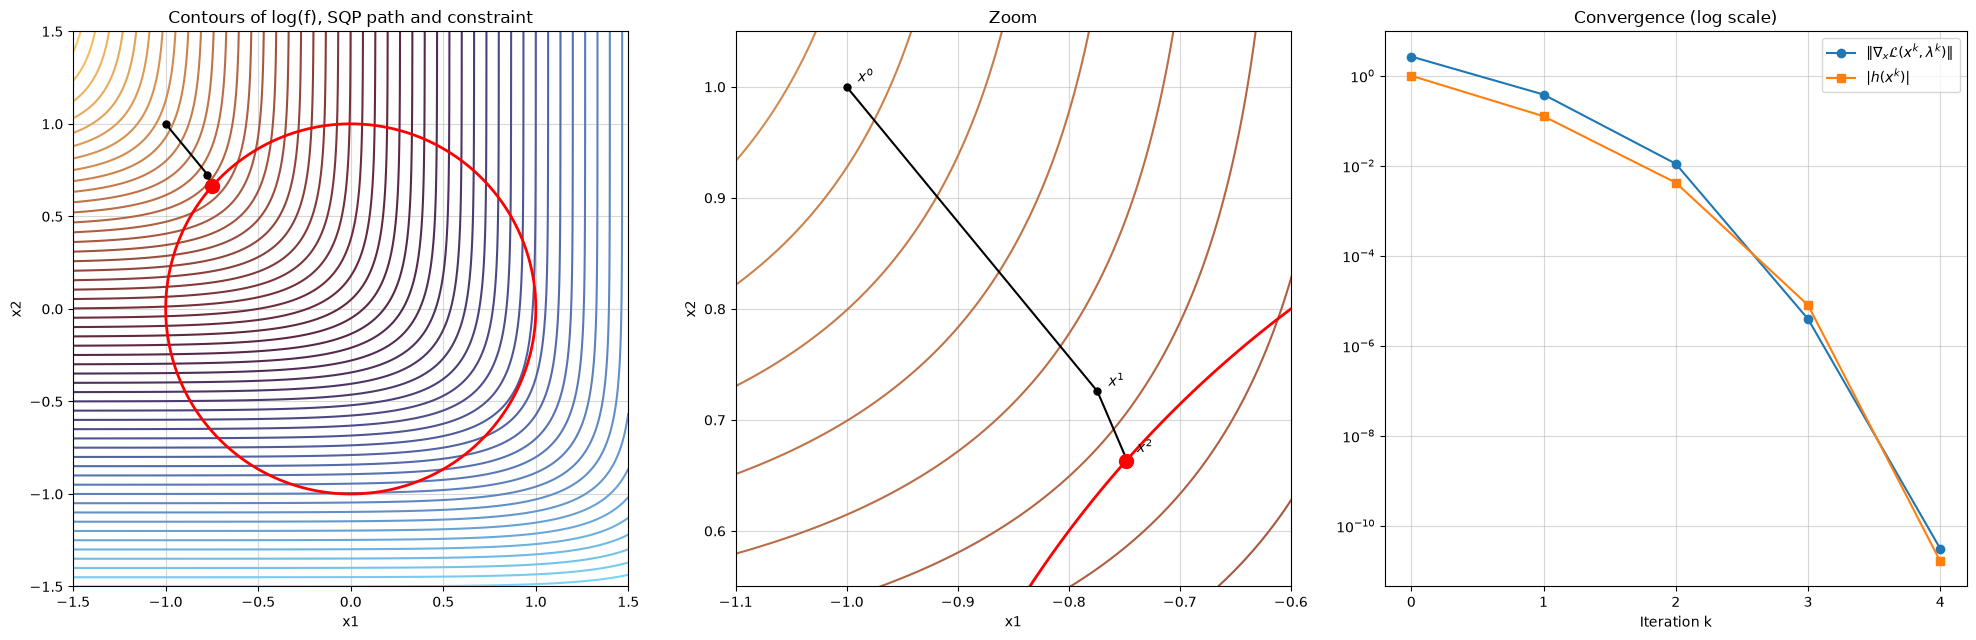

In [54]:
x1g, x2g = np.meshgrid(np.linspace(-1.5, 1.5, 400), np.linspace(-1.5, 1.5, 400))
Fg = np.exp(3*x1g) + np.exp(-4*x2g)
Hg = x1g**2 + x2g**2 - 1

fig, axs = plt.subplots(1, 3, figsize=(20, 6.5))

# Plot 1: Contours of log f, SQP path amd constraint
ax = axs[0]
ax.contour(x1g, x2g, np.log(Fg), levels=60, cmap="managua")
ax.contour(x1g, x2g, Hg, levels=[0], colors="red", linewidths=2)
ax.plot(path_x[:, 0], path_x[:, 1], "o-", color="black", ms=5, label="SQP iterates")
ax.plot(*x_ref, "o", color="red", ms=10, zorder=3, label="Reference solution")
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_aspect("equal")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("Contours of log(f), SQP path and constraint")
ax.grid(alpha=0.5)

# Plot 2: zoom around the solution
ax = axs[1]
ax.contour(x1g, x2g, np.log(Fg), levels=60, cmap="managua")
ax.contour(x1g, x2g, Hg, levels=[0], colors="red", linewidths=2)
ax.plot(path_x[:, 0], path_x[:, 1], "o-", color="black", ms=5, label="SQP iterates")
for k in range(3):
    ax.annotate(f"$x^{k}$", path_x[k], textcoords="offset points", xytext=(8, 4))
ax.plot(*x_ref, "o", color="red", ms=10, zorder=3, label="Reference solution")
ax.set_xlim(-1.1, -0.6)
ax.set_ylim(0.55, 1.05)
ax.set_aspect("equal")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("Zoom")
ax.grid(alpha=0.5)

# Plot 3: Norm of the gradient and h(x)
ax = axs[2]
ks = np.arange(len(norms_gradL))
ax.semilogy(ks, norms_gradL, "o-", label=r"$\|\nabla_x \mathcal{L}(x^k, \lambda^k)\|$")
ax.semilogy(ks, abs_h, "s-", label=r"$|h(x^k)|$")
ax.set_xticks(ks)
ax.set_xlabel("Iteration k")
ax.set_title("Convergence (log scale)")
ax.grid(alpha=0.5)
ax.legend()

plt.tight_layout()
plt.show()

### 1.2 Starting points farther from the solution

Now we define different starting points and each one of the paths. We still use the starting $\lambda^0 = -1$.

$$
x^0_1 = (0.5, -0.25) \qquad x^0_2 = (1.2, -1) \qquad x^0_3 = (1, 1) \qquad \lambda^0 = -1
$$

In [55]:
# Approx Claude prompt: Print the first 2 and last 2 steps of the SPQ for the starting points (0.5, -0.25), (1.2, -1) and (1, 1)
def print_sqp_table(path_x, path_lam, norms_gradL, abs_h, first=2, last=2):
    print(f"{'k':>3} | {'x1':>10} | {'x2':>10} | {'lambda':>10} | {'||grad_x L||':>12} | {'|h(x)|':>10} | {'f(x)':>8}")
    print("-" * 82)
    n = len(path_x)
    rows = list(range(n)) if n <= first + last else list(range(first)) + list(range(n - last, n))
    for i, k in enumerate(rows):
        if i > 0 and k != rows[i - 1] + 1:
            print("...")
        print(f"{k:>3} | {path_x[k,0]:>10.6f} | {path_x[k,1]:>10.6f} | {path_lam[k]:>10.6f} | {norms_gradL[k]:>12.3e} | {abs_h[k]:>10.3e} | {f(path_x[k]):>8.5f}")

starting_points = {"x⁰": np.array([-1.0, 1.0]),
                   "x⁰₁": np.array([0.5, -0.25]),
                   "x⁰₂": np.array([1.2, -1.0]),
                   "x⁰₃": np.array([1.0, 1.0])}

results_sqp = {}
for name, x_start in starting_points.items():
    results_sqp[name] = sqp(x_start, lam0=-1.0, alpha=1.0, tol=1e-6)

for name in ["x⁰₁", "x⁰₂", "x⁰₃"]:
    print(f"\nStarting point {name}")
    print_sqp_table(*results_sqp[name])


Starting point x⁰₁
  k |         x1 |         x2 |     lambda | ||grad_x L|| |     |h(x)| |     f(x)
----------------------------------------------------------------------------------
  0 |   0.500000 |  -0.250000 |  -1.000000 |    1.838e+01 |  6.875e-01 |  7.19997
  1 |   1.094750 |  -0.435500 |  38.623937 |    1.171e+01 |  3.881e-01 | 32.39772
...
  5 |   0.910413 |  -0.413700 |  25.293854 |    4.127e-06 |  2.306e-08 | 20.58394
  6 |   0.910413 |  -0.413700 |  25.293855 |    1.554e-12 |  8.438e-15 | 20.58394

Starting point x⁰₂
  k |         x1 |         x2 |     lambda | ||grad_x L|| |     |h(x)| |     f(x)
----------------------------------------------------------------------------------
  0 |   1.200000 |  -1.000000 |  -1.000000 |    2.473e+02 |  1.440e+00 | 91.19638
  1 |   0.820516 |  -0.735381 |  -6.650102 |    9.718e+01 |  2.140e-01 | 30.66762
...
  6 |   0.910412 |  -0.413703 |  25.293811 |    1.249e-04 |  6.822e-07 | 20.58396
  7 |   0.910413 |  -0.413700 |  25.293855 |    

We see that with starting points $(0.5, -0.25)$ and $(1.2, -1)$; the method converged to $(0.910, -0.414)$ which is a different point from the one that was given as reference. From our previous lab practices, we can deduce that the method converged to a local minimum instead of the global minimum (restricting $f$ to the constraint). Let's plot and check whether these path converge to a minimum of $f$ when seen as a function defined around the constraint, the unit circle.

In [56]:
# f restricted to the unit circle, f(cos(theta), sin(theta))
theta = np.linspace(-np.pi, np.pi, 1000, endpoint=False)
g_theta = np.exp(3*np.cos(theta)) + np.exp(-4*np.sin(theta))

def dg(t):
    return -3*np.sin(t)*np.exp(3*np.cos(t)) - 4*np.cos(t)*np.exp(-4*np.sin(t))

def d2g(t):
    return (-3*np.cos(t) + 9*np.sin(t)**2)*np.exp(3*np.cos(t)) + (4*np.sin(t) + 16*np.cos(t)**2)*np.exp(-4*np.sin(t))

# Finding critical points quickly using Newton's method 
roots = dg(theta)[dg(theta)*np.roll(dg(theta), -1) < 0] # Checking at which theta the derivative changes sign
for _ in range(50): # Then Newton
    roots = roots - dg(roots)/d2g(roots)
kkt_minima = roots[d2g(roots) > 0]
kkt_maxima = roots[d2g(roots) < 0]

Local minimum: (0.91041, -0.41370),  f = 20.58394
Local maximum: (0.99498, -0.10005),  f = 21.27758
Local maximum: (0.99498, -0.10005),  f = 21.27758
Local maximum: (0.99498, -0.10005),  f = 21.27758


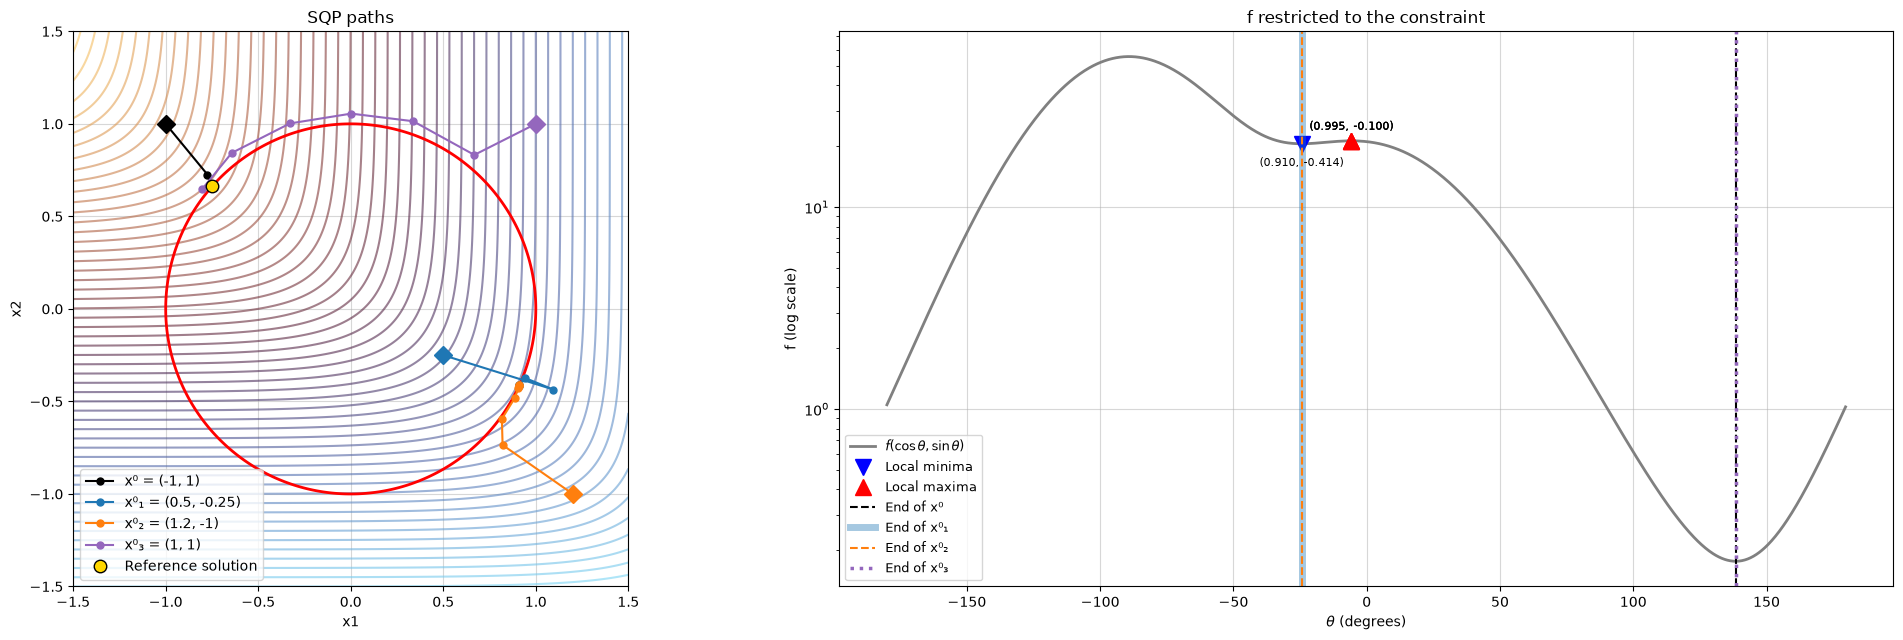

In [57]:
# Claude cleaned up the code to make it more understandable, speacilly when plotting the 4 paths
# Local minima and maxima of f on the circle, as points (x1, x2)
for kind, angles in [("Local minimum", kkt_minima), ("Local maximum", kkt_maxima)]:
    for th in np.atleast_1d(angles):
        x_pt = np.array([np.cos(th), np.sin(th)])
        print(f"{kind}: ({x_pt[0]:.5f}, {x_pt[1]:.5f}),  f = {f(x_pt):.5f}")

colors_sqp = {"x⁰": "black", "x⁰₁": "tab:blue", "x⁰₂": "tab:orange", "x⁰₃": "tab:purple"}

fig, axs = plt.subplots(1, 2, figsize=(21, 6.5))

# Paths over the contours of log f
ax = axs[0]
x1g, x2g = np.meshgrid(np.linspace(-1.5, 1.5, 400), np.linspace(-1.5, 1.5, 400))
ax.contour(x1g, x2g, np.log(np.exp(3*x1g) + np.exp(-4*x2g)), levels=60, cmap="managua", alpha=0.6)
ax.contour(x1g, x2g, x1g**2 + x2g**2 - 1, levels=[0], colors="red", linewidths=2)
for name, (px, pl, ng, ah) in results_sqp.items():
    x_s = starting_points[name]
    ax.plot(px[:, 0], px[:, 1], "o-", color=colors_sqp[name], ms=5, label=f"{name} = ({x_s[0]:g}, {x_s[1]:g})")
    ax.plot(*px[0], "D", color=colors_sqp[name], ms=9)
ax.plot(*x_ref, ".", color="gold", mec="black", ms=18, zorder=3, label="Reference solution")
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_aspect("equal")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("SQP paths")
ax.grid(alpha=0.5)
ax.legend(loc="lower left")

# f along the circle and where each run ends
ax = axs[1]
ax.semilogy(np.degrees(theta), g_theta, color="gray", lw=2, label=r"$f(\cos\theta, \sin\theta)$")
ax.plot(np.degrees(kkt_minima), np.exp(3*np.cos(kkt_minima)) + np.exp(-4*np.sin(kkt_minima)), "v", color="blue", ms=11, label="Local minima")
ax.plot(np.degrees(kkt_maxima), np.exp(3*np.cos(kkt_maxima)) + np.exp(-4*np.sin(kkt_maxima)), "^", color="red", ms=11, label="Local maxima")
# Coordinates (x1, x2) next to each triangle
for angles, dy in [(kkt_minima, -16), (kkt_maxima, 8)]:
    for th in np.atleast_1d(angles):
        x_pt = np.array([np.cos(th), np.sin(th)])
        ax.annotate(f"({x_pt[0]:.3f}, {x_pt[1]:.3f})", (np.degrees(th), f(x_pt)),
                    textcoords="offset points", xytext=(0, dy), ha="center", fontsize=8)
# x⁰₁ and x⁰₂ end at the same point, so the first one is drawn wider underneath
line_styles = {"x⁰": ("--", 1.5, 1.0), "x⁰₁": ("-", 5, 0.4), "x⁰₂": ("--", 1.5, 1.0), "x⁰₃": (":", 2.5, 1.0)}
for name, (px, pl, ng, ah) in results_sqp.items():
    th_end = np.arctan2(px[-1, 1], px[-1, 0])
    ls, lw, alpha = line_styles[name]
    ax.axvline(np.degrees(th_end), color=colors_sqp[name], ls=ls, lw=lw, alpha=alpha, label=f"End of {name}")
ax.set_xlabel(r"$\theta$ (degrees)")
ax.set_ylabel("f (log scale)")
ax.set_title("f restricted to the constraint")
ax.grid(alpha=0.5)
ax.legend(loc="lower left", fontsize=9)

plt.tight_layout()
plt.show()

As we predicted, $x_1$ and $x_3$ converged to a local minimum instead of the local minimum. We can see from the second plot that paths that stem from a point in the fourth quadrant of the 2D graph, might end up in the local minimum. The next section takes on a different approach to the SQO method in order to avoid finding local minimums.

### 1.3 Merit function: gradient descent with backtracking

Instead of applying Newton directly, we first minimize the quadratic penalty (merit) function:

$$
\mathcal{M}(x) = f(x) + \rho\, h(x)^2 \qquad
\nabla \mathcal{M}(x) = \nabla f(x) + 2\rho\, h(x)\, \nabla h(x)
$$

We will be using $\rho = 10$.

We reuse `grad_desc_backtracking` from Sessions 2 and 3 with two changes:
- The search direction is the normalized gradient $p^k = \nabla \mathcal{M}(x^k) / \|\nabla \mathcal{M}(x^k)\|$, so $\alpha^k$ is directly the length of the step and huge gradients (the exponentials of $f$) do not produce huge jumps.
- As in Session 3, if $\alpha$ reaches `alpha_min` without decreasing $\mathcal{M}$, we stop.

At every iteration $\alpha$ starts at 1 and is halved until $\mathcal{M}(x^k - \alpha^k p^k) < \mathcal{M}(x^k)$. We stop when $\|\nabla \mathcal{M}(x^k)\| < 10^{-5}$.

At a minimizer of $\mathcal{M}$ we have $\nabla f = -2\rho h \nabla h$, which compared with the KKT condition $\nabla f = \lambda \nabla h$ gives the estimate $\lambda \approx -2\rho\, h(x)$.

In [58]:
# When doing part 4, Claude proposed addind the stop_condition to the grad_desc_backtracking in order to make the switch to Newton easier, so there is no need to define a "switching" gradient descent
rho = 10

def M(x):
    return f(x) + rho*h(x)**2

def grad_M(x):
    return grad_f(x) + 2*rho*h(x)*grad_h(x)

def grad_desc_backtracking(f, grad_f, x0, alpha0=1, reset=True, normalize=True, tol=1e-6, max_iter=10000, alpha_min=1e-6, stop_condition=None):
    x = np.array(x0, dtype=float)
    path = [x]
    alphas = []
    n_halvings = 0
    alpha = alpha0
    for k in range(max_iter):
        grad = grad_f(x)
        if np.linalg.norm(grad) < tol:
            break
        if stop_condition is not None and stop_condition(k, x, grad): # Stopping rule used in 1.4 to switch to Newton
            break
        p = grad / np.linalg.norm(grad) if normalize else grad
        if reset:
            alpha = alpha0
        while f(x - alpha * p) >= f(x) and alpha > alpha_min:
            alpha = alpha / 2
            n_halvings += 1
        if f(x - alpha * p) >= f(x):
            break
        x = x - alpha * p
        path.append(x)
        alphas.append(alpha)
    return np.array(path), np.array(alphas), n_halvings

Let's see how the merit function performs:

In [59]:
results_merit = {}
for name, x_start in starting_points.items():
    results_merit[name] = grad_desc_backtracking(M, grad_M, x_start)

print(f"{'x0':>5} | {'Iter':>5} | {'halvings':>8} | {'x1':>9} | {'x2':>9} | {'||grad M||':>10} | {'h(x)':>9} | {'f(x)':>8} | {'-2 rho h':>9} | {'||x - x_ref||':>13}")
print("-" * 113)
for name, (px, alphas, n_halv) in results_merit.items():
    xm = px[-1]
    print(f"{name:>5} | {len(px) - 1:>5} | {n_halv:>8} | {xm[0]:>9.5f} | {xm[1]:>9.5f} | {np.linalg.norm(grad_M(xm)):>10.2e} | "
          f"{h(xm):>9.5f} | {f(xm):>8.5f} | {-2*rho*h(xm):>9.5f} | {np.linalg.norm(xm - x_ref):>13.5f}")
print(f"\nReference: x* = ({x_ref[0]}, {x_ref[1]}), lambda* = {lam_ref}, f(x*) = {f(x_ref):.5f}")

   x0 |  Iter | halvings |        x1 |        x2 | ||grad M|| |      h(x) |     f(x) |  -2 rho h | ||x - x_ref||
-----------------------------------------------------------------------------------------------------------------
   x⁰ |   184 |     2210 |  -0.75243 |   0.66654 |   1.74e-05 |   0.01043 |  0.17415 |  -0.20858 |       0.00521
  x⁰₁ |   244 |     2654 |  -0.75243 |   0.66655 |   2.05e-05 |   0.01043 |  0.17415 |  -0.20860 |       0.00521
  x⁰₂ |   218 |     2387 |  -0.75243 |   0.66655 |   1.38e-05 |   0.01043 |  0.17415 |  -0.20860 |       0.00521
  x⁰₃ |   226 |     2615 |  -0.75243 |   0.66654 |   3.91e-05 |   0.01043 |  0.17415 |  -0.20857 |       0.00521

Reference: x* = (-0.74834, 0.66332), lambda* = -0.21233, f(x*) = 0.17635


We see that all four merit functions halted almost at the same point $(-0.752..., 0.665...)$. They actually halted because of $\alpha$ reaching the tolerance, this urges us to think that convergence was slow, more precisely, that consequent steps were either not "directed" towards the minimum of $f$ or constantly overshooting the minimum. This is further noticeable by the low amount of steps (Iter) considering the high amount of halvings. Let's plot the paths and check,

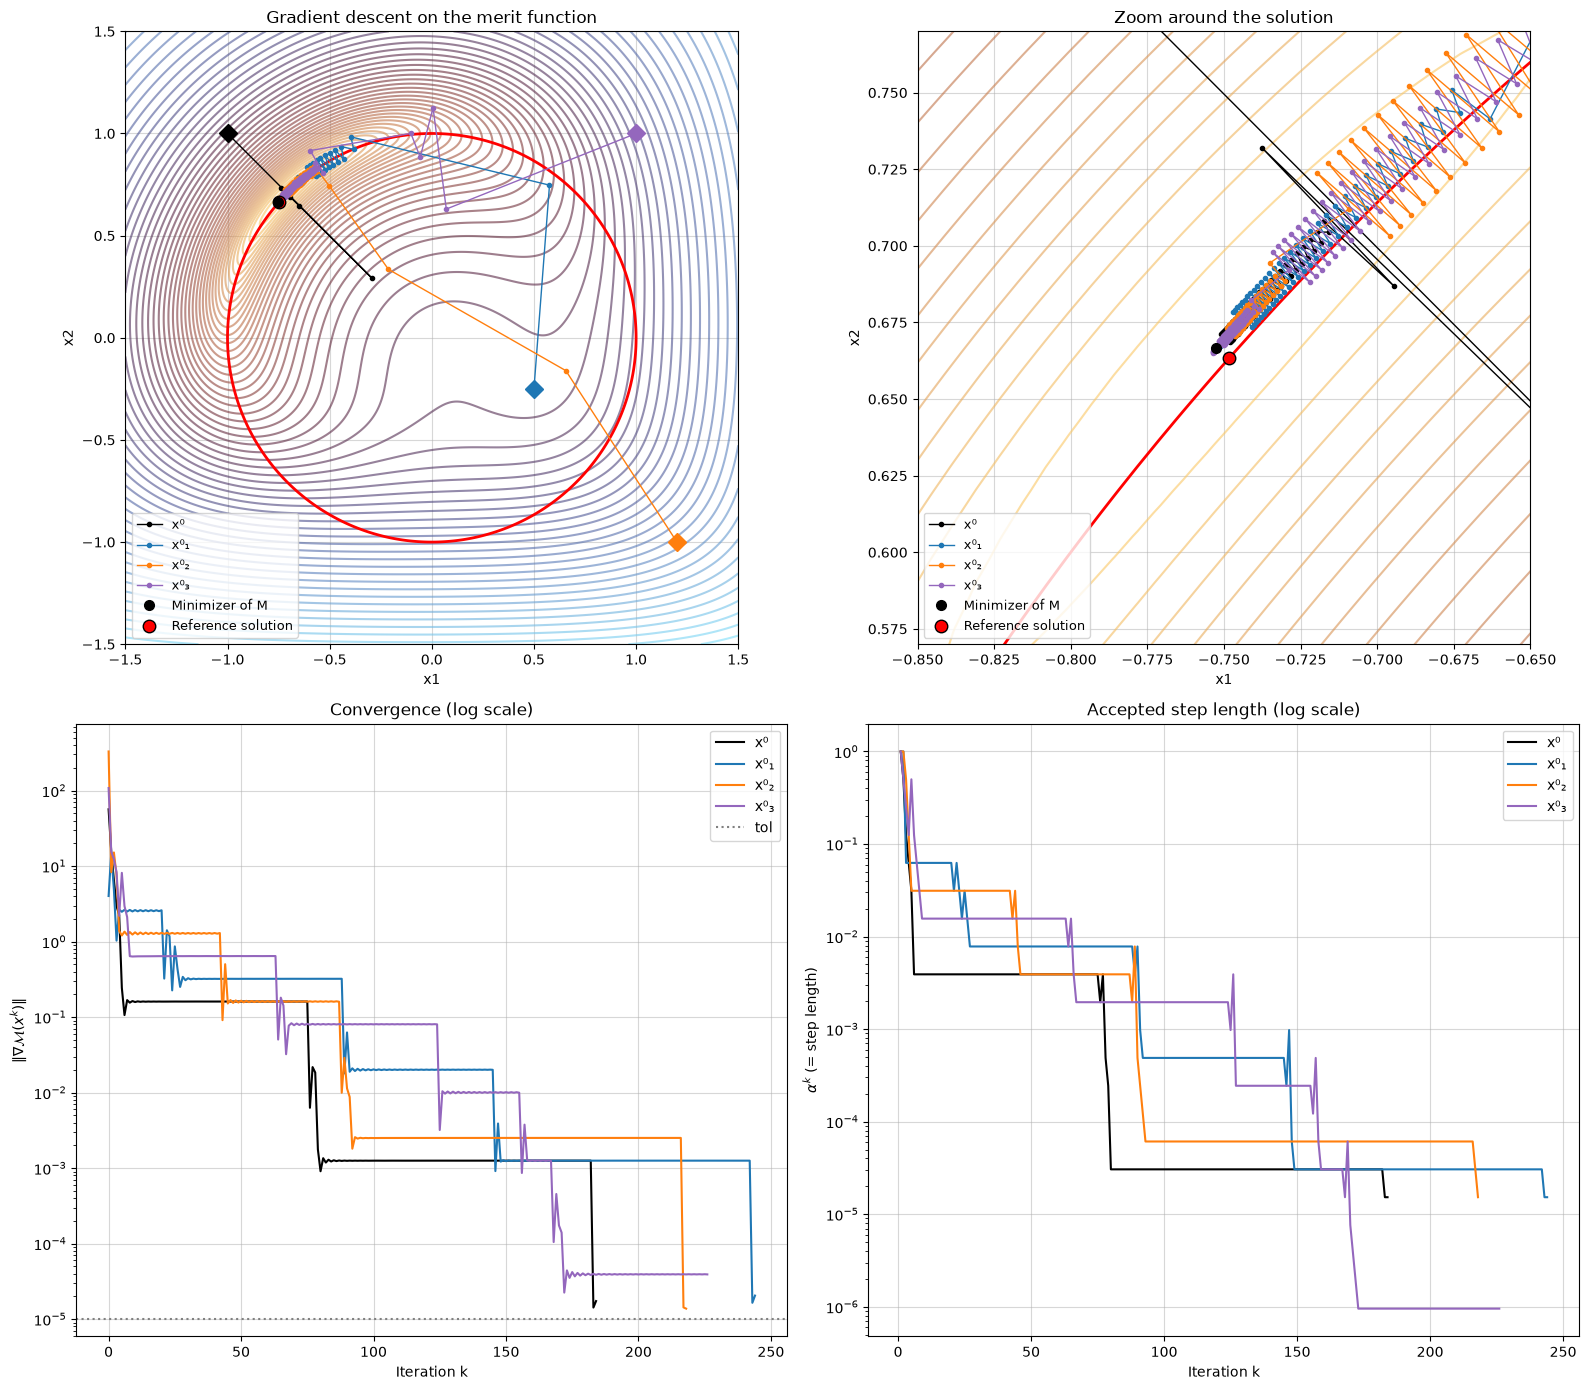

In [60]:
# Claude helped plot the 4 paths simultaneously
x1g, x2g = np.meshgrid(np.linspace(-1.5, 1.5, 400), np.linspace(-1.5, 1.5, 400))
Mg = np.exp(3*x1g) + np.exp(-4*x2g) + rho*(x1g**2 + x2g**2 - 1)**2

fig, axs = plt.subplots(2, 2, figsize=(16, 14))

# Paths over the contours of log M, full view and zoom
for ax, lims, title in [(axs[0, 0], (-1.5, 1.5, -1.5, 1.5), "Gradient descent on the merit function"),
                        (axs[0, 1], (-0.85, -0.65, 0.57, 0.77), "Zoom around the solution")]:
    ax.contour(x1g, x2g, np.log(Mg), levels=60, cmap="managua", alpha=0.6)
    ax.contour(x1g, x2g, x1g**2 + x2g**2 - 1, levels=[0], colors="red", linewidths=2)
    for name, (px, alphas, n_halv) in results_merit.items():
        ax.plot(px[:, 0], px[:, 1], "o-", color=colors_sqp[name], ms=3, lw=1, label=f"{name}")
        ax.plot(*px[0], "D", color=colors_sqp[name], ms=9)
    ax.plot(*results_merit["x⁰"][0][-1], ".", color="black", mec="black", ms=14, zorder=4, label="Minimizer of M")
    ax.plot(*x_ref, ".", color="red", mec="black", ms=18, zorder=3, label="Reference solution")
    ax.set_xlim(lims[0], lims[1])
    ax.set_ylim(lims[2], lims[3])
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(title)
    ax.grid(alpha=0.5)
    ax.legend(loc="lower left", fontsize=9)

# Convergence of ||grad M|| and accepted step lengths
for name, (px, alphas, n_halv) in results_merit.items():
    axs[1, 0].semilogy(np.arange(len(px)), [np.linalg.norm(grad_M(x)) for x in px], color=colors_sqp[name], label=f"{name}")
    axs[1, 1].semilogy(np.arange(1, len(alphas) + 1), alphas, color=colors_sqp[name], label=f"{name}")
axs[1, 0].axhline(1e-5, color="gray", ls=":", label="tol")
axs[1, 0].set_ylabel(r"$\|\nabla \mathcal{M}(x^k)\|$")
axs[1, 0].set_title("Convergence (log scale)")
axs[1, 1].set_ylabel(r"$\alpha^k$ (= step length)")
axs[1, 1].set_title("Accepted step length (log scale)")
for ax in axs[1]:
    ax.set_xlabel("Iteration k")
    ax.grid(alpha=0.5)
    ax.legend()

plt.tight_layout()
plt.show()

We observe the first case, the paths keep zigazgging getting ever so close to the minimum, choosing "not optimal" directions as they get close to the global minimum. As stated by the proposed experiment, the merit function is used to get close to the minimum, then, in 1.4 we will merge both methods to create a robust solution to the minimizing problem. Also the value of $\alpha$ is quite usual except when it sometimes return to a higher value.

Let's see how the merit function works:

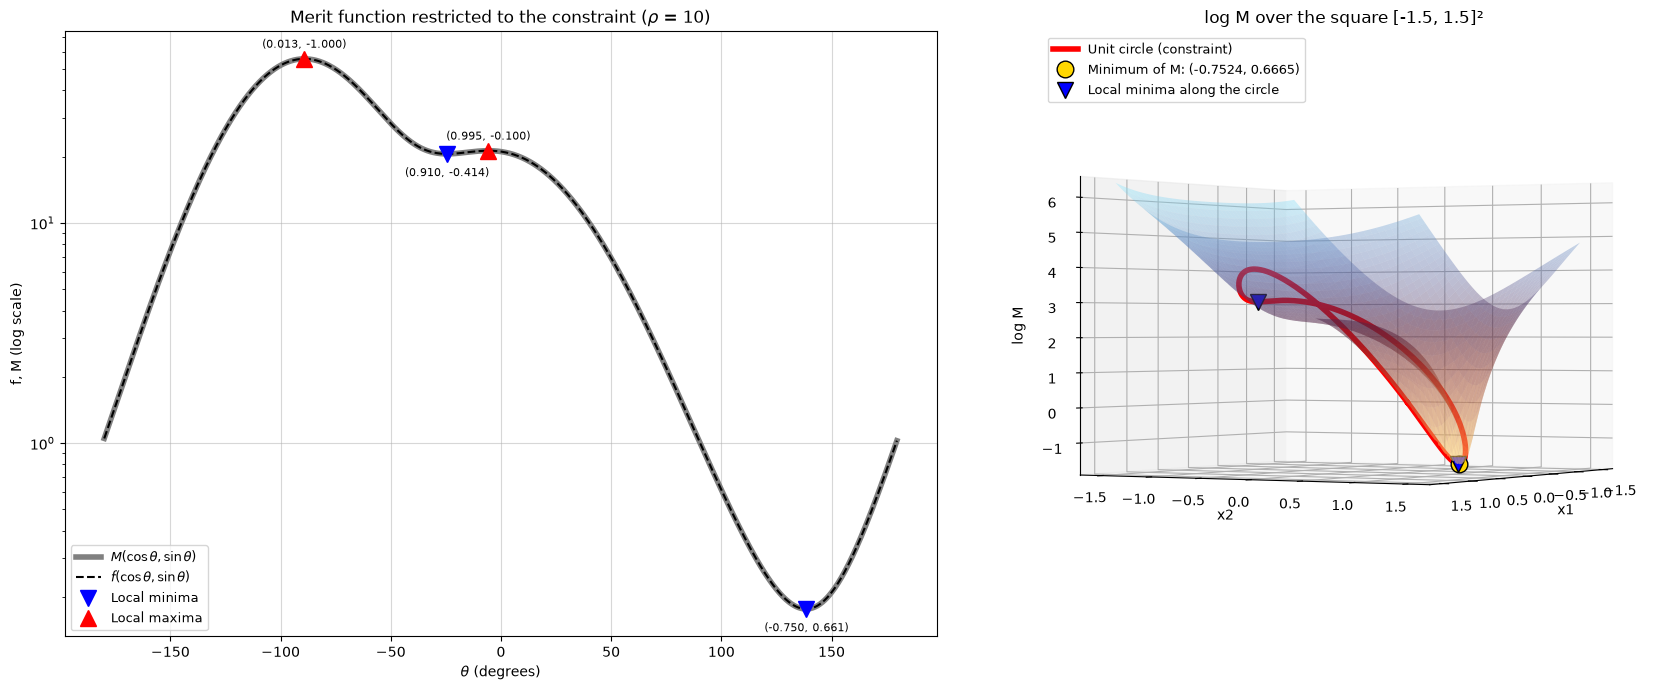

In [61]:
# Claude prompt: can you create 2 plots, one showing the plot of M arounf the circle (just as before) and another one in 3d showing the 3x3 square that shows the plot atound the circle in a red line and the real minimum
from scipy.optimize import minimize

# Merit function along the constraint (unit circle)
theta = np.linspace(-np.pi, np.pi, 1000, endpoint=False)
circle = np.column_stack([np.cos(theta), np.sin(theta)])
M_theta = np.array([M(x) for x in circle])
f_theta = np.array([f(x) for x in circle])

# Local minima / maxima of M along the circle (the circle is periodic)
prev, nxt = np.roll(M_theta, 1), np.roll(M_theta, -1)
idx_min = np.where((M_theta < prev) & (M_theta < nxt))[0]
idx_max = np.where((M_theta > prev) & (M_theta > nxt))[0]

# Real minimum of M in the plane (not restricted to the circle)
res = minimize(M, x0=[-0.75, 0.66], method="BFGS", options={"gtol": 1e-10})
x_min_M = res.x

# M over the 3x3 square (log scale, as M grows exponentially)
x1g, x2g = np.meshgrid(np.linspace(-1.5, 1.5, 200), np.linspace(-1.5, 1.5, 200))
Mg = np.exp(3*x1g) + np.exp(-4*x2g) + rho*(x1g**2 + x2g**2 - 1)**2

fig = plt.figure(figsize=(18, 7))

# Plot 1: M (and f) around the circle
ax = fig.add_subplot(1, 2, 1)
ax.semilogy(np.degrees(theta), M_theta, color="gray", lw=4, label=r"$M(\cos\theta, \sin\theta)$")
ax.semilogy(np.degrees(theta), f_theta, "k--", lw=1.5, label=r"$f(\cos\theta, \sin\theta)$")
ax.plot(np.degrees(theta[idx_min]), M_theta[idx_min], "v", color="blue", ms=11, label="Local minima")
ax.plot(np.degrees(theta[idx_max]), M_theta[idx_max], "^", color="red", ms=11, label="Local maxima")
for idx, dy in [(idx_min, -16), (idx_max, 8)]:
    for i in idx:
        ax.annotate(f"({circle[i, 0]:.3f}, {circle[i, 1]:.3f})", (np.degrees(theta[i]), M_theta[i]),
                    textcoords="offset points", xytext=(0, dy), ha="center", fontsize=8)
ax.set_xlabel(r"$\theta$ (degrees)")
ax.set_ylabel("f, M (log scale)")
ax.set_title(f"Merit function restricted to the constraint ($\\rho$ = {rho})")
ax.grid(alpha=0.5)
ax.legend(loc="lower left", fontsize=9)

# Plot 2: 3D surface of log M, the circle in red and the real minimum of M
ax = fig.add_subplot(1, 2, 2, projection="3d")
ax.view_init(elev=0, azim=30)
ax.plot_surface(x1g, x2g, np.log(Mg), cmap="managua", alpha=0.35, linewidth=0, antialiased=True)
ax.plot(circle[:, 0], circle[:, 1], np.log(M_theta), color="red", lw=4, label="Unit circle (constraint)")
ax.plot([x_min_M[0]], [x_min_M[1]], [np.log(M(x_min_M))], "o", color="gold", mec="black", ms=12,
        label=f"Minimum of M: ({x_min_M[0]:.4f}, {x_min_M[1]:.4f})")
ax.plot(circle[idx_min, 0], circle[idx_min, 1], np.log(M_theta[idx_min]), "v", color="blue", mec="black", ms=11,
        label="Local minima along the circle")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("log M")
ax.set_title("log M over the square [-1.5, 1.5]²")
ax.legend(loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()

With the merit funcion, what we are trying to minimize is the 3d plot, previously we wanted to minimize the funcion along the constraint, therefore a local minimum could be found. With $\rho = 10$ there is only one minimum as adding the $\rho h(x_{1},x_{2})^{2}$ component increases the function rapidly as we strand away from the constraint. And, due to the similarity of the $\mathcal{M}$ to $f$, the minimums are close together.

This method is not applicable with $f$, let's plot the 3d graph:

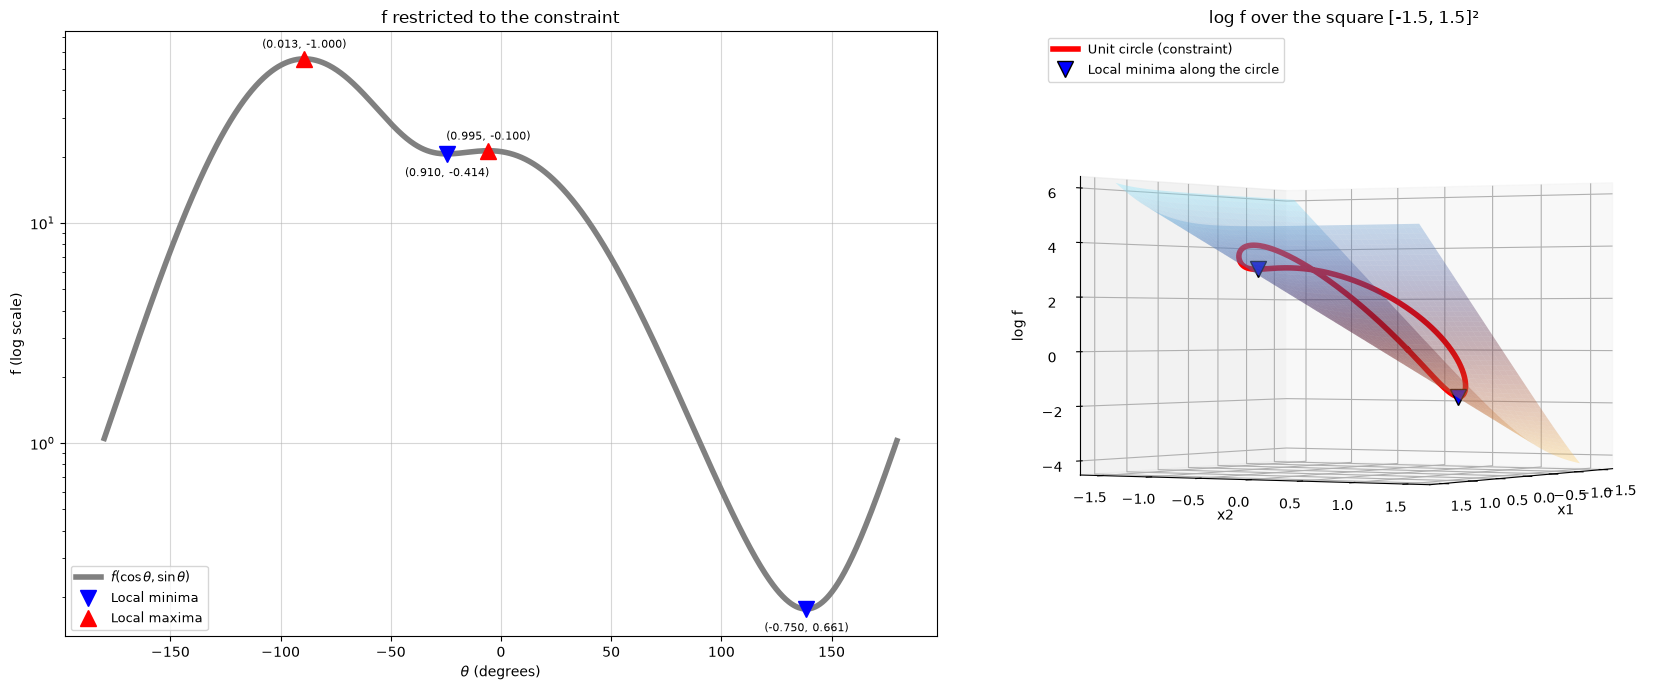

In [62]:
# f along the constraint (unit circle)
theta = np.linspace(-np.pi, np.pi, 1000, endpoint=False)
circle = np.column_stack([np.cos(theta), np.sin(theta)])
f_theta = np.array([f(x) for x in circle])

# Local minima / maxima of f along the circle (the circle is periodic)
prev, nxt = np.roll(f_theta, 1), np.roll(f_theta, -1)
idx_min = np.where((f_theta < prev) & (f_theta < nxt))[0]
idx_max = np.where((f_theta > prev) & (f_theta > nxt))[0]

# f over the 3x3 square (log scale, as f grows exponentially)
x1g, x2g = np.meshgrid(np.linspace(-1.5, 1.5, 200), np.linspace(-1.5, 1.5, 200))
Fg = np.exp(3*x1g) + np.exp(-4*x2g)

fig = plt.figure(figsize=(18, 7))

# Plot 1: f around the circle
ax = fig.add_subplot(1, 2, 1)
ax.semilogy(np.degrees(theta), f_theta, color="gray", lw=4, label=r"$f(\cos\theta, \sin\theta)$")
ax.plot(np.degrees(theta[idx_min]), f_theta[idx_min], "v", color="blue", ms=11, label="Local minima")
ax.plot(np.degrees(theta[idx_max]), f_theta[idx_max], "^", color="red", ms=11, label="Local maxima")
for idx, dy in [(idx_min, -16), (idx_max, 8)]:
    for i in idx:
        ax.annotate(f"({circle[i, 0]:.3f}, {circle[i, 1]:.3f})", (np.degrees(theta[i]), f_theta[i]),
                    textcoords="offset points", xytext=(0, dy), ha="center", fontsize=8)
ax.set_xlabel(r"$\theta$ (degrees)")
ax.set_ylabel("f (log scale)")
ax.set_title("f restricted to the constraint")
ax.grid(alpha=0.5)
ax.legend(loc="lower left", fontsize=9)

# Plot 2: 3D surface of log f, the circle in red and its local minima (f has no minimum in the plane)
ax = fig.add_subplot(1, 2, 2, projection="3d")
ax.view_init(elev=0, azim=30)
ax.plot_surface(x1g, x2g, np.log(Fg), cmap="managua", alpha=0.35, linewidth=0, antialiased=True)
ax.plot(circle[:, 0], circle[:, 1], np.log(f_theta), color="red", lw=4, label="Unit circle (constraint)")
ax.plot(circle[idx_min, 0], circle[idx_min, 1], np.log(f_theta[idx_min]), "v", color="blue", mec="black", ms=11,
        label="Local minima along the circle")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("log f")
ax.set_title("log f over the square [-1.5, 1.5]²")
ax.legend(loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()

As we can see, if we were to find a minimum in the 3D space, we won't reach it, or at least, not close to the minimum we are interested in. That is why we need to restrain ourselves to working only in the constraint.

What if we had chosen another value of $\rho$? Let's take $\rho = 50$:

Minima of M (rho = 50)
          minimum |        x1 |        x2 |      h(x) |      f(x) |      M(x) | ||grad M||
------------------------------------------------------------------------------------------
     Global plane |  -0.74917 |   0.66398 |   0.00212 |   0.17590 |   0.17612 |   2.83e-11
      Local plane |   0.83474 |  -0.28872 |  -0.21984 |  15.40782 |  17.82435 |   3.03e-09
Global constraint |  -0.74834 |   0.66332 |   0.00000 |   0.17635 |   0.17635 |   4.25e-01
 Local constraint |   0.91041 |  -0.41370 |   0.00000 |  20.58394 |  20.58394 |   5.06e+01


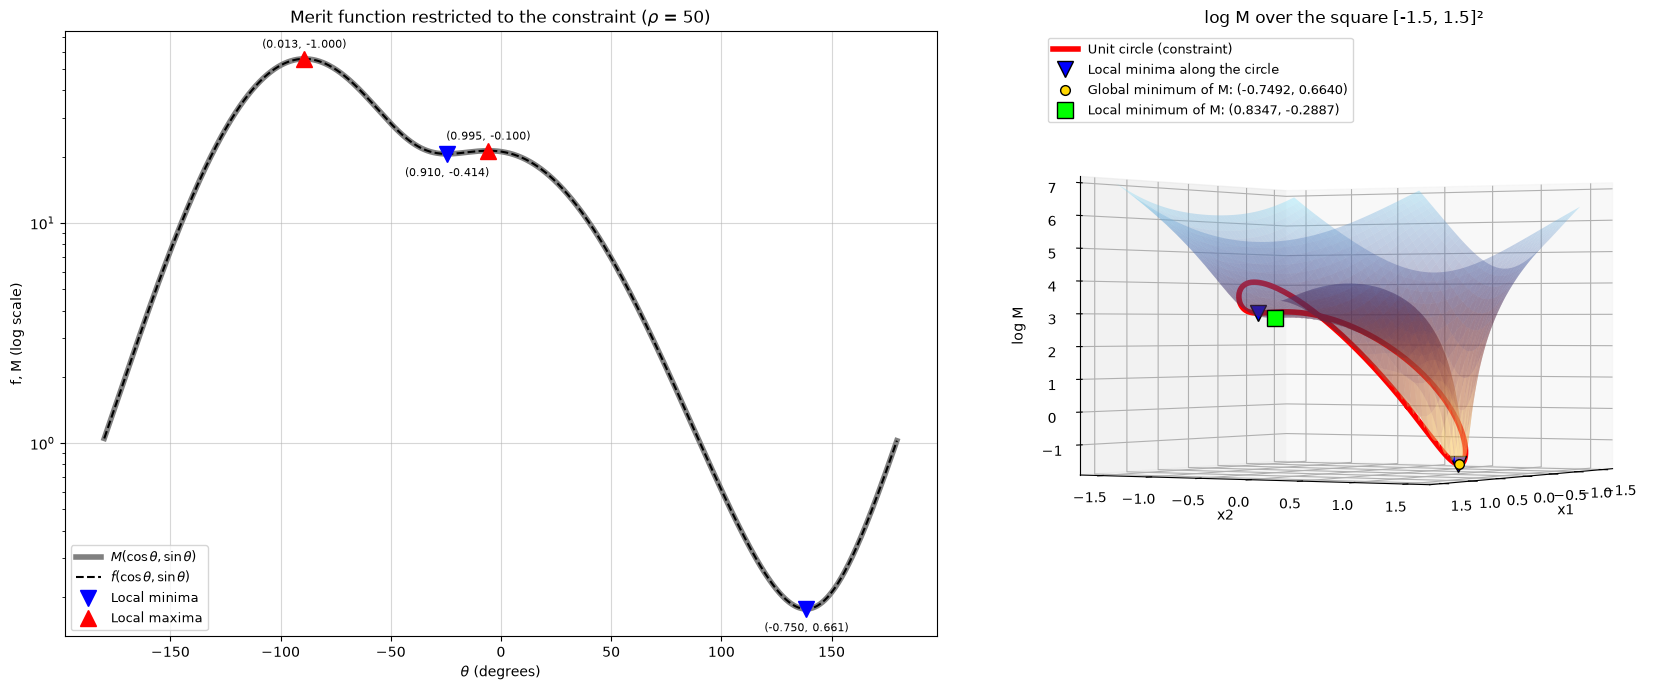

In [ ]:
# Claude prompt: can you create 2 plots, one showing the plot of M arounf the circle (just as before) and another one in 3d showing the 3x3 square that shows the plot atound the circle in a red line and the real minimum
rho = 50

# Merit function along the constraint (unit circle)
theta = np.linspace(-np.pi, np.pi, 1000, endpoint=False)
circle = np.column_stack([np.cos(theta), np.sin(theta)])
M_theta = np.array([M(x) for x in circle])
f_theta = np.array([f(x) for x in circle])

# Local minima / maxima of M along the circle (the circle is periodic)
prev, nxt = np.roll(M_theta, 1), np.roll(M_theta, -1)
idx_min = np.where((M_theta < prev) & (M_theta < nxt))[0]
idx_max = np.where((M_theta > prev) & (M_theta > nxt))[0]

# Minima of M in the plane (not restricted to the circle): minimize from several starting points
def hess_M(x):
    gh = grad_h(x)
    return hess_f(x) + 2*rho*(np.outer(gh, gh) + h(x)*hess_h(x))

starts = [(-1, 1), (0.5, -0.25), (1.2, -1), (1, 1), (0.9, -0.4), (0, -1), (1, -0.5), (-0.75, 0.66)]
minima_M = []
for x_start in starts:
    r = minimize(M, x_start, jac=grad_M, method="BFGS", options={"gtol": 1e-10})
    if np.all(np.linalg.eigvalsh(hess_M(r.x)) > 0) and not any(np.linalg.norm(r.x - p) < 1e-4 for p in minima_M):
        minima_M.append(r.x)
minima_M.sort(key=M)           # lowest M first: the first one is the global minimum
x_min_M = minima_M[0]          # global minimum of M
kinds = ["Global"] + ["Local"]*(len(minima_M) - 1)

# Minima of M restricted to the constraint (unit circle), refined around each minimum found on the circle
M_angle = lambda t: M(np.array([np.cos(t), np.sin(t)]))
minima_C = []
for i in idx_min:
    t_min = minimize_scalar(M_angle, bounds=(theta[i] - 0.05, theta[i] + 0.05), method="bounded",
                            options={"xatol": 1e-12}).x
    minima_C.append(np.array([np.cos(t_min), np.sin(t_min)]))
minima_C.sort(key=M)
kinds_C = ["Global"] + ["Local"]*(len(minima_C) - 1)

# Table with the minima of M in the plane and along the constraint
rows = ([(f"{k} plane", xm) for k, xm in zip(kinds, minima_M)]
        + [(f"{k} constraint", xm) for k, xm in zip(kinds_C, minima_C)])
header = (f"{'minimum':>17} | {'x1':>9} | {'x2':>9} | {'h(x)':>9} | {'f(x)':>9} | {'M(x)':>9} | "
          f"{'||grad M||':>10}")
print(f"Minima of M (rho = {rho})")
print(header)
print("-" * len(header))
for name, xm in rows:
    print(f"{name:>17} | {xm[0]:>9.5f} | {xm[1]:>9.5f} | {round(h(xm), 12) + 0.0:>9.5f} | {f(xm):>9.5f} | {M(xm):>9.5f} | "
          f"{np.linalg.norm(grad_M(xm)):>10.2e}")

# M over the 3x3 square (log scale, as M grows exponentially)
x1g, x2g = np.meshgrid(np.linspace(-1.5, 1.5, 200), np.linspace(-1.5, 1.5, 200))
Mg = np.exp(3*x1g) + np.exp(-4*x2g) + rho*(x1g**2 + x2g**2 - 1)**2

fig = plt.figure(figsize=(18, 7))

# Plot 1: M (and f) around the circle
ax = fig.add_subplot(1, 2, 1)
ax.semilogy(np.degrees(theta), M_theta, color="gray", lw=4, label=r"$M(\cos\theta, \sin\theta)$")
ax.semilogy(np.degrees(theta), f_theta, "k--", lw=1.5, label=r"$f(\cos\theta, \sin\theta)$")
ax.plot(np.degrees(theta[idx_min]), M_theta[idx_min], "v", color="blue", ms=11, label="Local minima")
ax.plot(np.degrees(theta[idx_max]), M_theta[idx_max], "^", color="red", ms=11, label="Local maxima")
for idx, dy in [(idx_min, -16), (idx_max, 8)]:
    for i in idx:
        ax.annotate(f"({circle[i, 0]:.3f}, {circle[i, 1]:.3f})", (np.degrees(theta[i]), M_theta[i]),
                    textcoords="offset points", xytext=(0, dy), ha="center", fontsize=8)
ax.set_xlabel(r"$\theta$ (degrees)")
ax.set_ylabel("f, M (log scale)")
ax.set_title(f"Merit function restricted to the constraint ($\\rho$ = {rho})")
ax.grid(alpha=0.5)
ax.legend(loc="lower left", fontsize=9)

# Plot 2: 3D surface of log M, the circle in red and the minima of M in the plane
ax = fig.add_subplot(1, 2, 2, projection="3d")
ax.view_init(elev=0, azim=30)
ax.plot_surface(x1g, x2g, np.log(Mg), cmap="managua", alpha=0.35, linewidth=0, antialiased=True)
ax.plot(circle[:, 0], circle[:, 1], np.log(M_theta), color="red", lw=4, label="Unit circle (constraint)")
ax.plot(circle[idx_min, 0], circle[idx_min, 1], np.log(M_theta[idx_min]), "v", color="blue", mec="black", ms=11,
        label="Local minima along the circle")
styles = {"Global": dict(marker="o", color="gold", ms=7), "Local": dict(marker="s", color="lime", ms=12)}
for kind, xm in zip(kinds, minima_M):
    ax.plot([xm[0]], [xm[1]], [np.log(M(xm))], ls="", mec="black", zorder=10, **styles[kind],
            label=f"{kind} minimum of M: ({xm[0]:.4f}, {xm[1]:.4f})")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("log M")
ax.set_title("log M over the square [-1.5, 1.5]²")
ax.legend(loc="upper left", fontsize=9)

plt.tight_layout()
plt.show()

With $\rho = 50$ there is a new local minimum in the plane that the starting point could converge to:

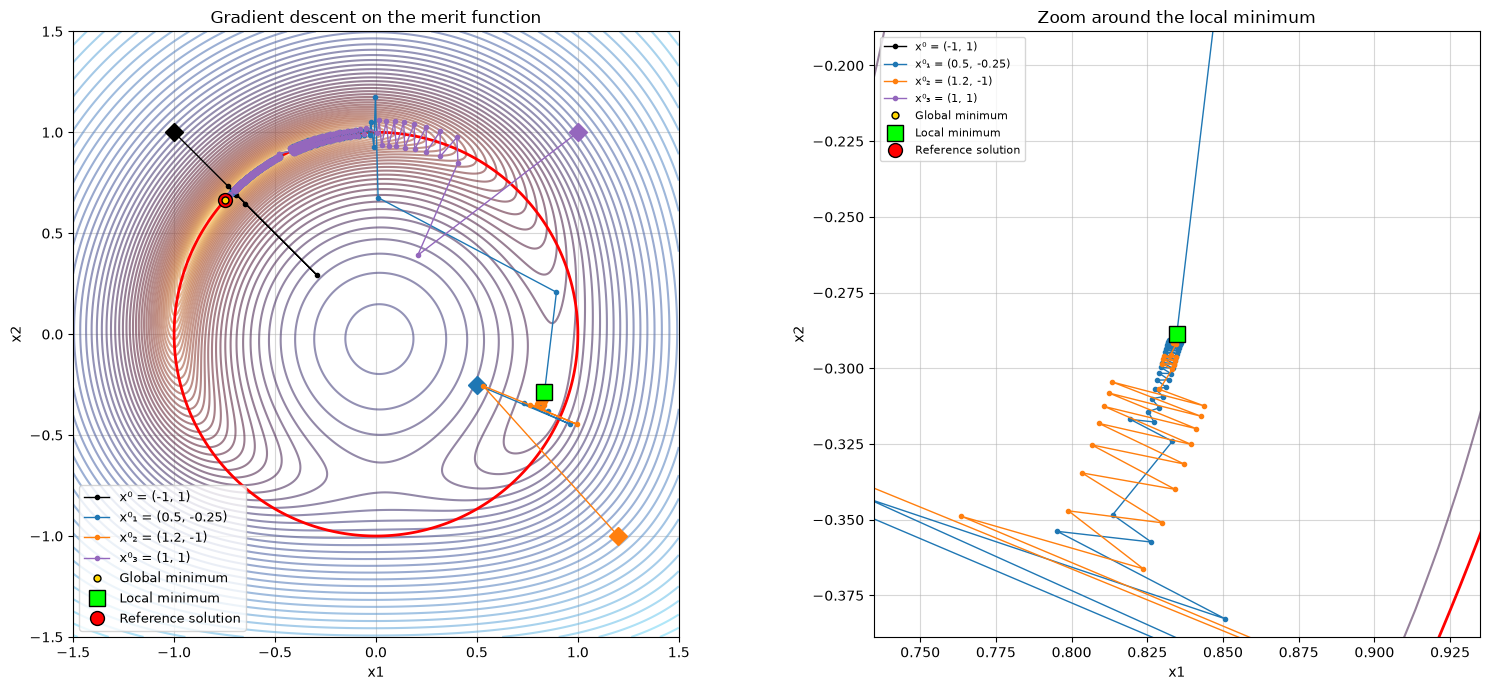

In [64]:
# Claude helped plot the 4 paths simultaneously
x1g, x2g = np.meshgrid(np.linspace(-1.5, 1.5, 400), np.linspace(-1.5, 1.5, 400))
Mg = np.exp(3*x1g) + np.exp(-4*x2g) + rho*(x1g**2 + x2g**2 - 1)**2

# Gradient descent with backtracking on the merit function, from the 4 starting points
results_four = {name: grad_desc_backtracking(M, grad_M, x_start) for name, x_start in starting_points.items()}

# Minima of M in the plane (minima_M, kinds) come from the cell with the table of minima above
min_styles = {"Global": dict(marker="o", color="gold", ms=5), "Local": dict(marker="s", color="lime", ms=12)}

def plot_paths(ax, lims, title):
    ax.contour(x1g, x2g, np.log(Mg), levels=60, cmap="managua", alpha=0.6)
    ax.contour(x1g, x2g, x1g**2 + x2g**2 - 1, levels=[0], colors="red", linewidths=2)
    for name, (px, alphas, n_halv) in results_four.items():
        x_s = starting_points[name]
        ax.plot(px[:, 0], px[:, 1], "o-", color=colors_sqp[name], ms=3, lw=1, label=f"{name} = ({x_s[0]:g}, {x_s[1]:g})")
        ax.plot(*px[0], "D", color=colors_sqp[name], ms=9)
    for kind, xm in zip(kinds, minima_M):
        ax.plot(*xm, ls="", mec="black", zorder=4, label=f"{kind} minimum", **min_styles[kind])
    ax.plot(*x_ref, ".", color="red", mec="black", ms=20, zorder=3, label="Reference solution")
    ax.set_xlim(lims[0], lims[1])
    ax.set_ylim(lims[2], lims[3])
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(title)
    ax.grid(alpha=0.5)

fig, axs = plt.subplots(1, 2, figsize=(16, 7))

# Plot 1: full view
plot_paths(axs[0], (-1.5, 1.5, -1.5, 1.5), "Gradient descent on the merit function")
axs[0].legend(loc="lower left", fontsize=9)

# Plot 2: zoom around the local minimum
x_loc = minima_M[1] if len(minima_M) > 1 else minima_M[0]
half = 0.1
plot_paths(axs[1], (x_loc[0] - half, x_loc[0] + half, x_loc[1] - half, x_loc[1] + half),
           "Zoom around the local minimum")
axs[1].legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

We can see that $(1.2, -1)$, in orange, converged to the new local minimum of the merit function, whereas $(0.5, -0.25)$, in blue, got "saved" by the fact that we reset the value of $\alpha$ at each iteration. The other points converged as they did in the case of $\rho = 10$.

### 1.4 Merit function + Newton (SQP)

We start with the gradient descent with backtracking on $\mathcal{M}$ of 1.3 and, once a switch condition is reached, we continue with the SQP Newton iteration ($\alpha^k = 1$, stopping when $\|\nabla_x \mathcal{L}\| < 10^{-6}$). We try three switch conditions:

- Distance: $\|x^k - x_{\text{ref}}\| < 0.4$
- Steps: $k = 7$ gradient steps done
- Tolerance: $\|\nabla_x \mathcal{L}(x^k, \hat\lambda^k)\| < 10\mathrm{e}{-1} = 1$, the same quantity used as stopping criterion in Newton. As we are approximating, we should try to find 

As we do not have a multiplier during the gradient phase, we use a plausible calculation of $\lambda$ at each step, in order to approximate $\nabla_{x}\mathcal{L} = \nabla f - \lambda \nabla h = 0$:

$$\hat\lambda^k = \frac{\nabla h(x^k)^T \nabla f(x^k)}{\|\nabla h(x^k)\|^2}$$

(With $\lambda = -2\rho h(x)$ instead, $\nabla_x \mathcal{L} = \nabla f + 2\rho h \nabla h = \nabla \mathcal{M}$, which would be the same as checking the gradient of the merit function.)

Each condition is a parameter of `merit_then_newton` (`None` = not used). If several are given, we switch as soon as any of them holds. The initial multiplier for Newton is the estimate from 1.3, $\lambda^0 = -2\rho\, h(x^{\text{switch}})$, unless `lam0` is given.

In [109]:
rho = 10

In [121]:
def merit_then_newton(x0, switch_distance=None, switch_steps=None, switch_tol=None, lam0=None, x_ref=x_ref, tol_newton=1e-6, max_iter_gd=10000):
    def switch(k, x, grad):
        return ((switch_distance is not None and np.linalg.norm(x - x_ref) < switch_distance) or
                (switch_steps is not None and k >= switch_steps) or
                (switch_tol is not None and np.linalg.norm(grad) < switch_tol))   # grad = grad M(x)

    # Phase 1: gradient descent with backtracking on the merit function
    path_gd, alphas, n_halvings = grad_desc_backtracking(M, grad_M, x0, max_iter=max_iter_gd, stop_condition=switch)
    x_switch = path_gd[-1]

    # Phase 2: Newton (SQP with alpha = 1) from the switch point

    if lam0 is None:
        lam0 = -2*rho*h(x_switch)
    path_x, path_lam, norms_gradL, abs_h = sqp(x_switch, lam0=lam0, alpha=1.0, tol=tol_newton)
    return {"path_gd": path_gd, "n_halvings": n_halvings, "lam0": lam0,
            "path_x": path_x, "path_lam": path_lam, "norms_gradL": norms_gradL, "abs_h": abs_h}

In [128]:
# Claude prompt (edit): distance to 0.4, steps to 10, tolerance on the gradient of the Lagrangian (least squares lambda)
# Claude prompt: now we want to do experiment 4: try 3 switch conditions to the newton method (switch_distance = 0.25, switch_steps = 30, switch_tolerance = 10e-1), make the function so we can change this parameters easily
switch_distance = 0.4
switch_steps = 7
switch_tolerance = 2

switch_options = {f"distance < {switch_distance}": dict(switch_distance=switch_distance),
                  f"steps = {switch_steps}": dict(switch_steps=switch_steps),
                  f"||grad M|| < {switch_tolerance}": dict(switch_tol=switch_tolerance)}

results_hybrid = {opt: {name: merit_then_newton(x_start, **kwargs) for name, x_start in starting_points.items()}
                  for opt, kwargs in switch_options.items()}

for opt, res in results_hybrid.items():
    print(f"\nSwitch condition: {opt}")
    print(f"{'x0':>13} | {'GD iter':>7} | {'x switch':>20} | {'||x_sw - x_ref||':>16} | {'lambda0':>8} | {'Newton iter':>11} | {'x*':>20} | {'lambda*':>9} | {'||grad_x L||':>12}")
    print("-" * 137)
    for name, r in res.items():
        xs, xe = r["path_gd"][-1], r["path_x"][-1]
        print(f"{name:>13} | {len(r['path_gd']) - 1:>7} | {f'({xs[0]:.5f}, {xs[1]:.5f})':>20} | {np.linalg.norm(xs - x_ref):>16.5f} | {r['lam0']:>8.4f} | "
              f"{len(r['path_x']) - 1:>11} | {f'({xe[0]:.5f}, {xe[1]:.5f})':>20} | {r['path_lam'][-1]:>9.5f} | {r['norms_gradL'][-1]:>12.2e}")
print(f"\nReference: x* = ({x_ref[0]}, {x_ref[1]}), lambda* = {lam_ref}")


Switch condition: distance < 0.4
           x0 | GD iter |             x switch | ||x_sw - x_ref|| |  lambda0 | Newton iter |                   x* |   lambda* | ||grad_x L||
-----------------------------------------------------------------------------------------------------------------------------------------
           x⁰ |       2 |  (-0.64785, 0.64504) |          0.10214 |   3.2842 |           4 |  (-0.74834, 0.66332) |  -0.21232 |     6.50e-07
          x⁰₁ |       5 |  (-0.43191, 0.87434) |          0.38034 |   0.9797 |          13 |  (-0.74834, 0.66332) |  -0.21232 |     1.66e-07
          x⁰₂ |       3 |  (-0.50140, 0.74300) |          0.25948 |   3.9310 |           5 |  (-0.74834, 0.66332) |  -0.21232 |     3.30e-07
          x⁰₃ |       5 |  (-0.59518, 0.91636) |          0.29578 |  -3.8792 |           5 |  (-0.74834, 0.66332) |  -0.21232 |     1.35e-08

Switch condition: steps = 7
           x0 | GD iter |             x switch | ||x_sw - x_ref|| |  lambda0 | Newton iter |  

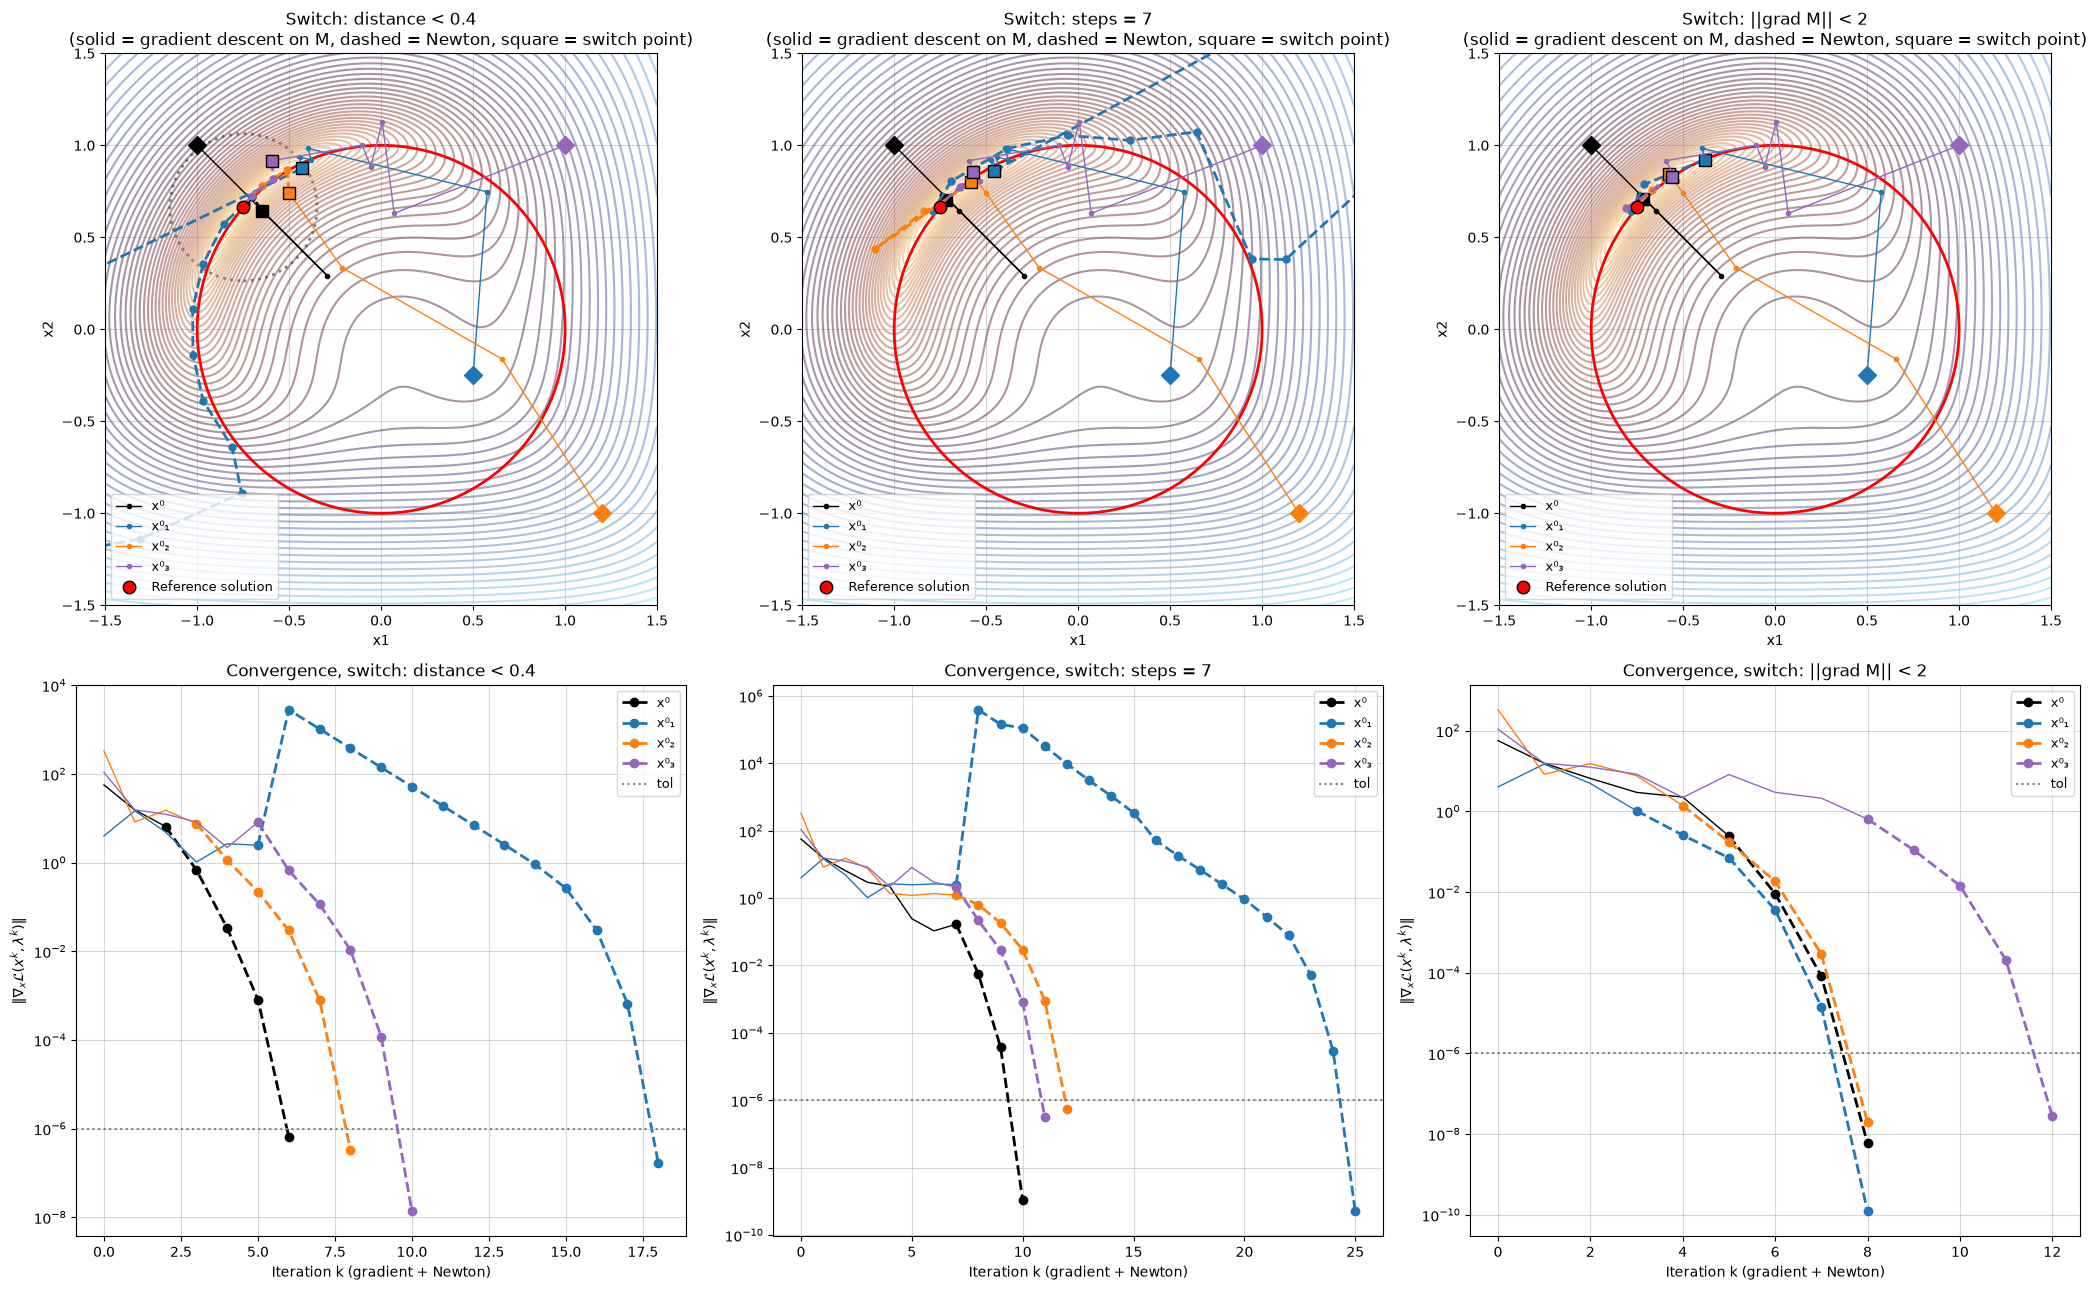

In [129]:
# Claude prompt: now we want to do experiment 4: try 3 switch conditions to the newton method (switch_distance = 0.25, switch_steps = 30, switch_tolerance = 10e-1), make the function so we can change this parameters easily
x1g, x2g = np.meshgrid(np.linspace(-1.5, 1.5, 400), np.linspace(-1.5, 1.5, 400))
Mg = np.exp(3*x1g) + np.exp(-4*x2g) + rho*(x1g**2 + x2g**2 - 1)**2

fig, axs = plt.subplots(2, 3, figsize=(21, 13))
for j, (opt, res) in enumerate(results_hybrid.items()):
    # Paths: solid = gradient descent on M, dashed = Newton
    ax = axs[0, j]
    ax.contour(x1g, x2g, np.log(Mg), levels=60, cmap="managua", alpha=0.5)
    ax.contour(x1g, x2g, x1g**2 + x2g**2 - 1, levels=[0], colors="red", linewidths=2)
    if "distance" in opt:
        ax.add_patch(plt.Circle(x_ref, switch_distance, fill=False, ls=":", color="gray", lw=2))
    for name, r in res.items():
        pg, px = r["path_gd"], r["path_x"]
        ax.plot(pg[:, 0], pg[:, 1], "o-", color=colors_sqp[name], ms=3, lw=1, label=f"{name}")
        ax.plot(px[:, 0], px[:, 1], "o--", color=colors_sqp[name], ms=5, lw=2)
        ax.plot(*pg[0], "D", color=colors_sqp[name], ms=9)
        ax.plot(*pg[-1], "s", color=colors_sqp[name], mec="black", ms=8)
    ax.plot(*x_ref, ".", color="red", mec="black", ms=18, zorder=3, label="Reference solution")
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(f"Switch: {opt}\n(solid = gradient descent on M, dashed = Newton, square = switch point)")
    ax.grid(alpha=0.5)
    ax.legend(loc="lower left", fontsize=9)

    # Convergence: ||grad_x L|| along the whole run (gradient phase uses lambda = -2 rho h(x))
    ax = axs[1, j]
    for name, r in res.items():
        pg = r["path_gd"]
        ng_gd = [np.linalg.norm(grad_L(x, -2*rho*h(x))) for x in pg]
        n_gd = len(pg) - 1
        ax.semilogy(np.arange(n_gd + 1), ng_gd, "-", color=colors_sqp[name], lw=1)
        ax.semilogy(np.arange(n_gd, n_gd + len(r["norms_gradL"])), r["norms_gradL"], "o--", color=colors_sqp[name], lw=2, label=f"{name}")
    ax.axhline(1e-6, color="gray", ls=":", label="tol")
    ax.set_xlabel("Iteration k (gradient + Newton)")
    ax.set_ylabel(r"$\|\nabla_x \mathcal{L}(x^k, \lambda^k)\|$")
    ax.set_title(f"Convergence, switch: {opt}")
    ax.grid(alpha=0.5)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

In [113]:
# Claude prompt: add a cell below that shows the value of the hessian at the steps around the switch point
# Claude prompt (edit): add a column that says if the hessian is positive definite, use 3 decimals and fix the column spacing
# Hessian of the Lagrangian hess_xx L = hess f - lambda hess h at the last gradient steps, the switch point and the first Newton steps.
# In the gradient phase there is no multiplier, so we use the estimate lambda = -2 rho h(x) (the one given to Newton at the switch).
# t^T H t is the curvature along the tangent of the circle (tangent_curvature from 1.2): it must be > 0 at a minimum.
# pos. def. = both eigenvalues of hess_xx L are > 0.
n_around = 2
w = 8  # width of each number inside the matrix / eigenvalue columns

for opt, res in results_hybrid.items():
    print(f"\n=== Switch condition: {opt} ===")
    for name, r in res.items():
        pg, px, pl = r["path_gd"], r["path_x"], r["path_lam"]
        n_gd = len(pg) - 1
        steps = [("gradient", n_gd + i, pg[n_gd + i], -2*rho*h(pg[n_gd + i])) for i in range(-n_around, 0) if n_gd + i >= 0]
        steps += [("switch" if i == 0 else "Newton", n_gd + i, px[i], pl[i]) for i in range(min(n_around + 1, len(px)))]
        print(f"\n{name}")
        header = (f"{'phase':>8} | {'k':>3} | {'x':^18} | {'lambda':>9} | {'hess_xx L':^{4*w + 12}} | "
                  f"{'eigenvalues':^{2*w + 4}} | {'t^T H t':>9} | {'pos. def.':>9}")
        print(header)
        print("-" * len(header))
        for phase, k, x, lam in steps:
            H = hess_L(x, lam)
            eig = np.linalg.eigvalsh(H)
            print(f"{phase:>8} | {k:>3} | ({x[0]:>7.3f}, {x[1]:>7.3f}) | {lam:>9.3f} | "
                  f"[[{H[0,0]:>{w}.3f}, {H[0,1]:>{w}.3f}], [{H[1,0]:>{w}.3f}, {H[1,1]:>{w}.3f}]] | "
                  f"({eig[0]:>{w}.3f}, {eig[1]:>{w}.3f}) | {tangent_curvature(x, lam):>9.3f} | {'yes' if eig[0] > 0 else 'no':>9}")



=== Switch condition: distance < 0.4 ===

x⁰
   phase |   k |         x          |    lambda |                  hess_xx L                   |     eigenvalues      |   t^T H t | pos. def.
---------------------------------------------------------------------------------------------------------------------------------------------
gradient |   0 | ( -1.000,   1.000) |   -20.000 | [[  40.448,    0.000], [   0.000,   40.293]] | (  40.293,   40.448) |    40.371 |       yes
gradient |   1 | ( -0.294,   0.292) |    16.569 | [[ -29.407,    0.000], [   0.000,  -28.166]] | ( -29.407,  -28.166) |   -28.783 |        no
  switch |   2 | ( -0.648,   0.645) |     3.284 | [[  -5.280,    0.000], [   0.000,   -5.356]] | (  -5.356,   -5.280) |    -5.318 |        no
  Newton |   3 | ( -0.700,   0.720) |    -0.545 | [[   2.191,    0.000], [   0.000,    1.989]] | (   1.989,    2.191) |     2.093 |       yes
  Newton |   4 | ( -0.734,   0.681) |    -0.209 | [[   1.414,    0.000], [   0.000,    1.468]] | (   1

> **TODO (our comments):** compare the three switch conditions (gradient iterations before switching, Newton iterations after, where the switch point is), whether all of them reach the reference solution, compare with 1.2 (Newton alone) and 1.3 (merit function alone), and discuss which condition can be used in practice (the distance condition needs to know the solution beforehand).

### 1.5 Merit function + Newton SQP with protection

Same mechanism as 1.4 (gradient descent with backtracking on $\mathcal{M}$, then SQP Newton with $\alpha^k = 1$), but Newton is only used where $\nabla^2_{xx}\mathcal{L}(x^k, \lambda^k)$ is positive definite:

- **At the switch:** we only switch when the switch condition holds **and** $\nabla^2_{xx}\mathcal{L}(x^k, -2\rho\, h(x^k))$ is positive definite. Otherwise we keep doing gradient steps on $\mathcal{M}$.
- **During Newton:** if at some iterate $\nabla^2_{xx}\mathcal{L}(x^k, \lambda^k)$ is not positive definite, we go back to gradient descent on $\mathcal{M}$ until $\nabla^2_{xx}\mathcal{L}(x, -2\rho\, h(x))$ is positive definite again. Then we restart Newton with $\lambda = -2\rho\, h(x)$.

Positive definite = both eigenvalues of $\nabla^2_{xx}\mathcal{L}$ are $> 0$.

In [ ]:
# Claude prompt: make a new cell at the bottom that has the same mechanisms, but if the hessian isn't positive definite, it keeps going with the merit function until it is positive again. call it, merit function + Newton SQP with protection
def is_pos_def(x, lam):
    return np.linalg.eigvalsh(hess_L(x, lam))[0] > 0

def lam_merit(x):
    return -2*rho*h(x)

def merit_then_newton_protected(x0, switch_distance=None, switch_steps=None, switch_tol=None,
                                x_ref=x_ref, tol_newton=1e-6, max_iter_gd=10000, max_iter=100):
    # Same switch conditions as 1.4, plus: hess_xx L must be positive definite at the switch point
    def switch(k, x, grad):
        cond = ((switch_distance is not None and np.linalg.norm(x - x_ref) < switch_distance) or
                (switch_steps is not None and k >= switch_steps) or
                (switch_tol is not None and np.linalg.norm(grad) < switch_tol))   # grad = grad M(x)
        return cond and is_pos_def(x, lam_merit(x))

    # Stop the merit fallback as soon as the Hessian is positive definite again
    def back_to_pos_def(k, x, grad):
        return is_pos_def(x, lam_merit(x))

    # Phase 1: gradient descent with backtracking on the merit function
    path_gd, alphas, n_halvings = grad_desc_backtracking(M, grad_M, x0, max_iter=max_iter_gd, stop_condition=switch)
    x = path_gd[-1].copy()
    lam = lam_merit(x)
    lam0 = lam

    # Phase 2: Newton, falling back to the merit function when hess_xx L is not positive definite
    path_x, path_lam, phases = [x.copy()], [lam], ["switch"]
    norms_gradL, abs_h = [np.linalg.norm(grad_L(x, lam))], [abs(h(x))]
    n_fallbacks = 0
    for _ in range(max_iter):
        if norms_gradL[-1] < tol_newton:
            break
        if not is_pos_def(x, lam):
            n_fallbacks += 1
            path_m, _, nh = grad_desc_backtracking(M, grad_M, x, max_iter=max_iter_gd, stop_condition=back_to_pos_def)
            n_halvings += nh
            for xm in path_m[1:]:
                path_x.append(xm.copy())
                path_lam.append(lam_merit(xm))
                phases.append("merit")
                norms_gradL.append(np.linalg.norm(grad_L(xm, lam_merit(xm))))
                abs_h.append(abs(h(xm)))
            x = path_m[-1].copy()
            lam = lam_merit(x)  # restart Newton with the merit estimate of lambda
            if not is_pos_def(x, lam):  # the merit function could not recover positive definiteness
                break
        A, b = kkt_system(x, lam)
        sol = np.linalg.solve(A, b)
        x = x + sol[:2]
        lam = lam + sol[2]
        path_x.append(x.copy())
        path_lam.append(lam)
        phases.append("Newton")
        norms_gradL.append(np.linalg.norm(grad_L(x, lam)))
        abs_h.append(abs(h(x)))

    return {"path_gd": path_gd, "n_halvings": n_halvings, "lam0": lam0, "n_fallbacks": n_fallbacks,
            "path_x": np.array(path_x), "path_lam": np.array(path_lam), "phases": np.array(phases),
            "norms_gradL": np.array(norms_gradL), "abs_h": np.array(abs_h)}

In [115]:
# Claude prompt: make a new cell at the bottom that has the same mechanisms, but if the hessian isn't positive definite, it keeps going with the merit function until it is positive again. call it, merit function + Newton SQP with protection
# Same switch conditions as in 1.4
results_protected = {opt: {name: merit_then_newton_protected(x_start, **kwargs) for name, x_start in starting_points.items()}
                     for opt, kwargs in switch_options.items()}

for opt, res in results_protected.items():
    print(f"\nSwitch condition: {opt} (with protection)")
    header = (f"{'x0':>13} | {'GD iter':>7} | {'x switch':^18} | {'lambda0':>8} | {'fallbacks':>9} | {'merit iter':>10} | "
              f"{'Newton iter':>11} | {'Newton iter 1.4':>15} | {'x*':^18} | {'lambda*':>8} | {'||grad_x L||':>12}")
    print(header)
    print("-" * len(header))
    for name, r in res.items():
        xs, xe = r["path_gd"][-1], r["path_x"][-1]
        n_merit = np.sum(r["phases"] == "merit")
        n_newton = np.sum(r["phases"] == "Newton")
        n_newton_14 = len(results_hybrid[opt][name]["path_x"]) - 1
        print(f"{name:>13} | {len(r['path_gd']) - 1:>7} | ({xs[0]:>7.3f}, {xs[1]:>7.3f}) | {r['lam0']:>8.3f} | {r['n_fallbacks']:>9} | {n_merit:>10} | "
              f"{n_newton:>11} | {n_newton_14:>15} | ({xe[0]:>7.3f}, {xe[1]:>7.3f}) | {r['path_lam'][-1]:>8.3f} | {r['norms_gradL'][-1]:>12.2e}")
print(f"\nReference: x* = ({x_ref[0]}, {x_ref[1]}), lambda* = {lam_ref}")


Switch condition: distance < 0.4 (with protection)
           x0 | GD iter |      x switch      |  lambda0 | fallbacks | merit iter | Newton iter | Newton iter 1.4 |         x*         |  lambda* | ||grad_x L||
---------------------------------------------------------------------------------------------------------------------------------------------------------------
           x⁰ |       3 | ( -0.738,   0.732) |   -1.599 |         0 |          0 |           4 |               4 | ( -0.748,   0.663) |   -0.212 |     1.15e-10
          x⁰₁ |       6 | ( -0.474,   0.921) |   -1.442 |         0 |          0 |           5 |              13 | ( -0.748,   0.663) |   -0.212 |     9.02e-10
          x⁰₂ |       4 | ( -0.577,   0.842) |   -0.856 |         0 |          0 |           4 |               5 | ( -0.748,   0.663) |   -0.212 |     2.00e-08
          x⁰₃ |       5 | ( -0.595,   0.916) |   -3.879 |         0 |          0 |           5 |               5 | ( -0.748,   0.663) |   -0.212 |  

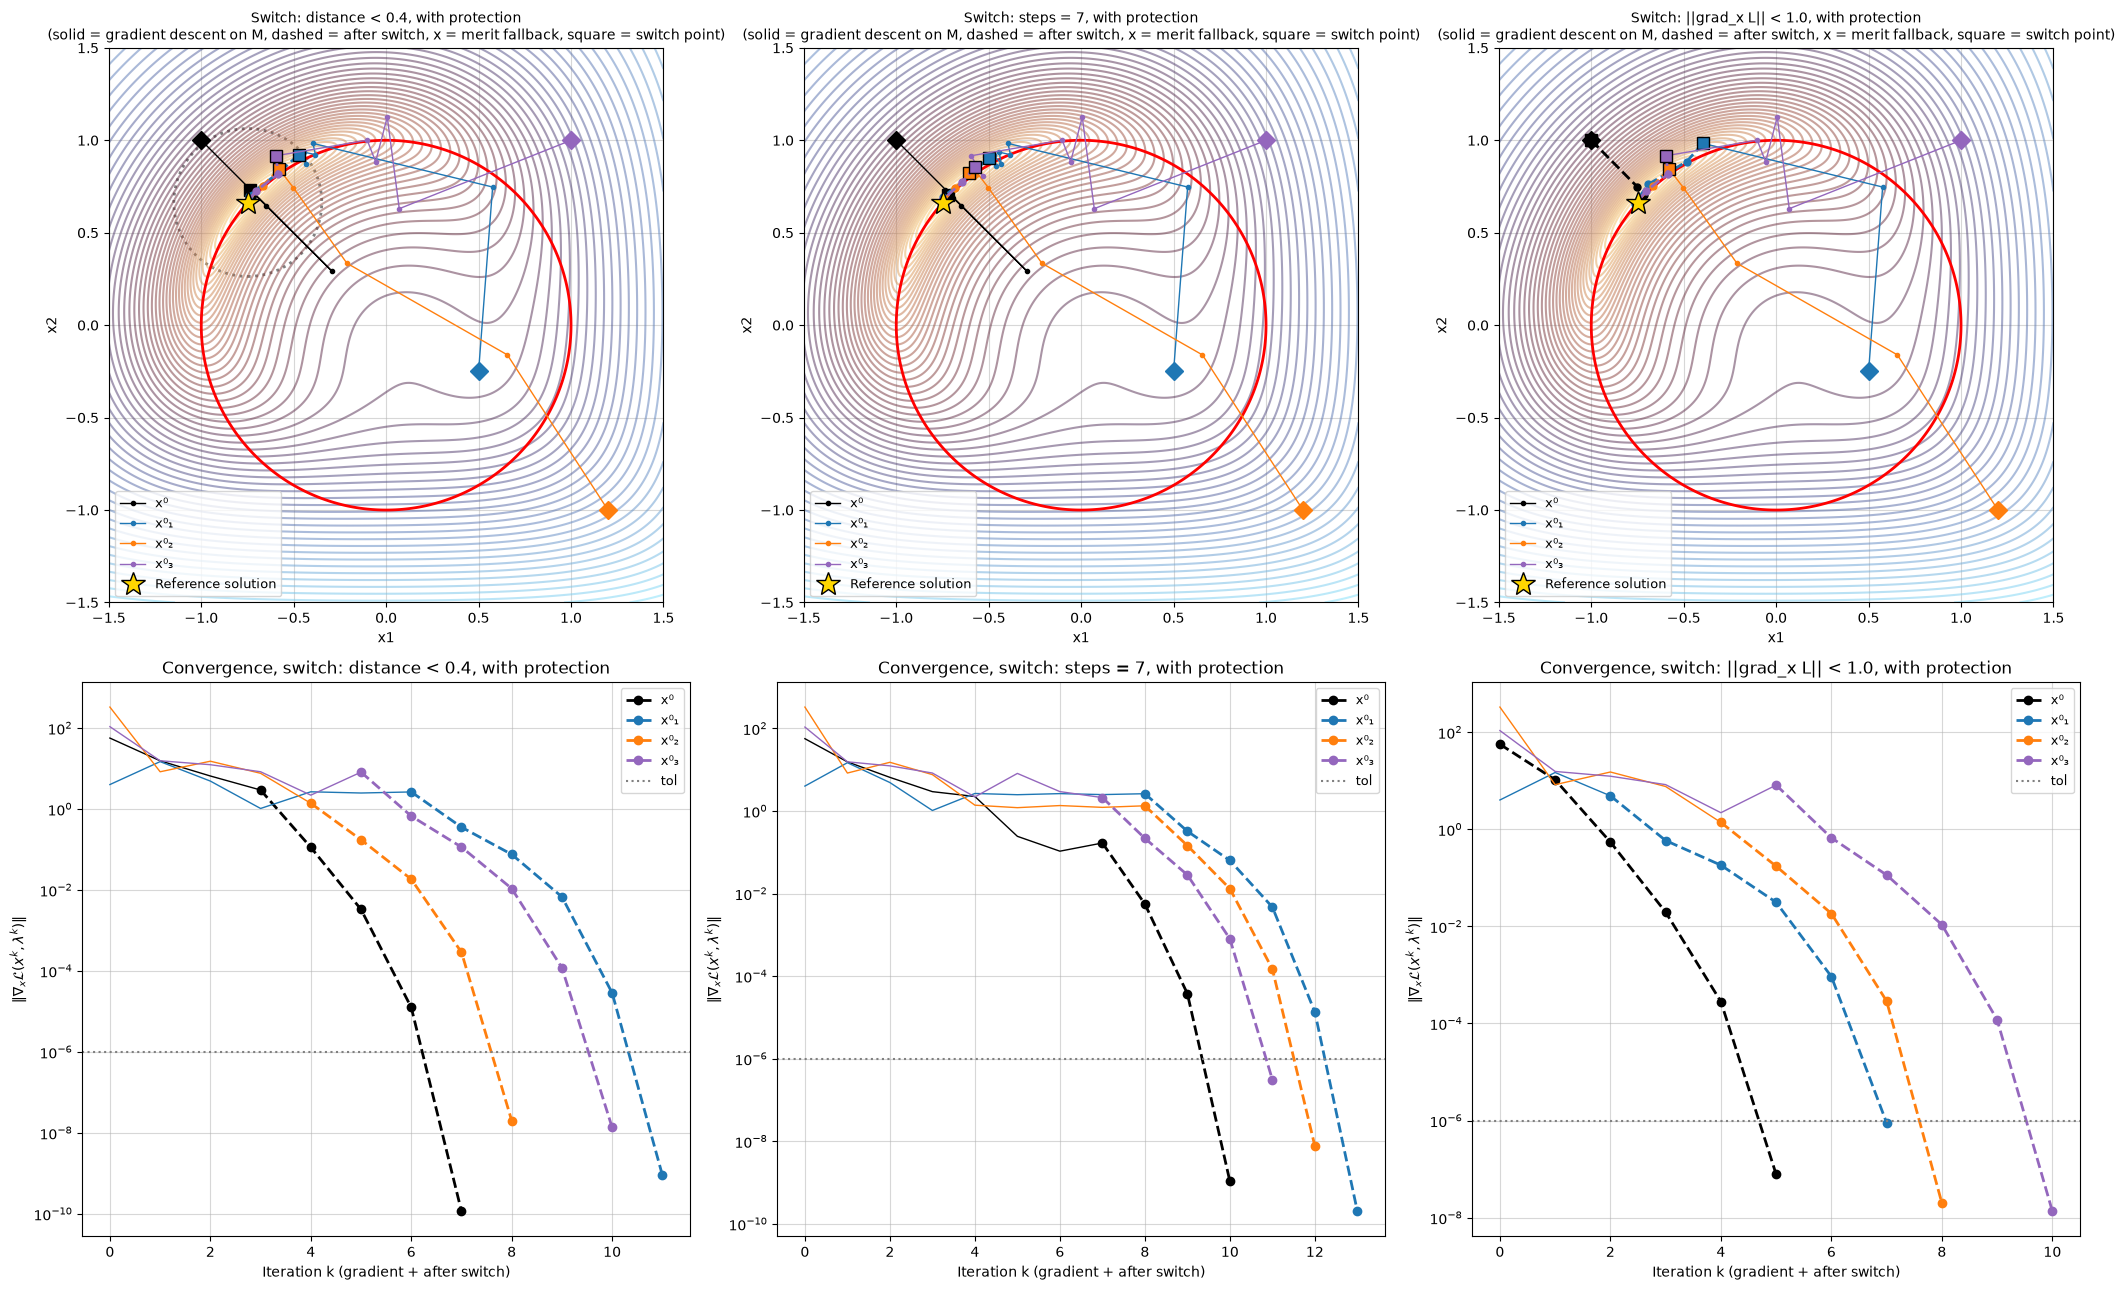

In [116]:
# Claude prompt: make a new cell at the bottom that has the same mechanisms, but if the hessian isn't positive definite, it keeps going with the merit function until it is positive again. call it, merit function + Newton SQP with protection
x1g, x2g = np.meshgrid(np.linspace(-1.5, 1.5, 400), np.linspace(-1.5, 1.5, 400))
Mg = np.exp(3*x1g) + np.exp(-4*x2g) + rho*(x1g**2 + x2g**2 - 1)**2

fig, axs = plt.subplots(2, 3, figsize=(21, 13))
for j, (opt, res) in enumerate(results_protected.items()):
    # Paths: solid = gradient descent on M, dashed = after the switch (Newton + merit fallbacks marked with x)
    ax = axs[0, j]
    ax.contour(x1g, x2g, np.log(Mg), levels=60, cmap="managua", alpha=0.5)
    ax.contour(x1g, x2g, x1g**2 + x2g**2 - 1, levels=[0], colors="red", linewidths=2)
    if "distance" in opt:
        ax.add_patch(plt.Circle(x_ref, switch_distance, fill=False, ls=":", color="gray", lw=2))
    for name, r in res.items():
        pg, px, ph = r["path_gd"], r["path_x"], r["phases"]
        ax.plot(pg[:, 0], pg[:, 1], "o-", color=colors_sqp[name], ms=3, lw=1, label=f"{name}")
        ax.plot(px[:, 0], px[:, 1], "o--", color=colors_sqp[name], ms=5, lw=2)
        ax.plot(px[ph == "merit", 0], px[ph == "merit", 1], "x", color=colors_sqp[name], mec="black", ms=10, mew=2)
        ax.plot(*pg[0], "D", color=colors_sqp[name], ms=9)
        ax.plot(*pg[-1], "s", color=colors_sqp[name], mec="black", ms=8)
    ax.plot(*x_ref, "*", color="gold", mec="black", ms=18, zorder=3, label="Reference solution")
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(f"Switch: {opt}, with protection\n(solid = gradient descent on M, dashed = after switch, x = merit fallback, square = switch point)", fontsize=10)
    ax.grid(alpha=0.5)
    ax.legend(loc="lower left", fontsize=9)

    # Convergence: ||grad_x L|| along the whole run (merit steps use lambda = -2 rho h(x))
    ax = axs[1, j]
    for name, r in res.items():
        pg, ph = r["path_gd"], r["phases"]
        ng_gd = [np.linalg.norm(grad_L(x, lam_merit(x))) for x in pg]
        n_gd = len(pg) - 1
        ks = np.arange(n_gd, n_gd + len(r["norms_gradL"]))
        ax.semilogy(np.arange(n_gd + 1), ng_gd, "-", color=colors_sqp[name], lw=1)
        ax.semilogy(ks, r["norms_gradL"], "o--", color=colors_sqp[name], lw=2, label=f"{name}")
        ax.semilogy(ks[ph == "merit"], r["norms_gradL"][ph == "merit"], "x", color=colors_sqp[name], mec="black", ms=10, mew=2)
    ax.axhline(1e-6, color="gray", ls=":", label="tol")
    ax.set_xlabel("Iteration k (gradient + after switch)")
    ax.set_ylabel(r"$\|\nabla_x \mathcal{L}(x^k, \lambda^k)\|$")
    ax.set_title(f"Convergence, switch: {opt}, with protection")
    ax.grid(alpha=0.5)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()